## Image Processing and Computer Vision - Assignment Module #2


Alessandro Teodori (0001247539) alessandro.teodori3@studio.unibo.it

Juan Guillermo Jaramillo Saa (0001217725) juan.jaramillosaa@studio.unibo.it

Ubalducci Michele (0001226810) michele.ubalducci@studio.unibo.it

# Part 1: design your own network

### Contents

**Setup and code** (shared by all parts)
- [Setup](#setup-shared-by-all-parts) — [Paths](#paths), [Reproducibility](#reproducibility)
- [Configuration](#configuration)
- [Data](#data)
- [The network](#the-network)
- [Training](#training) — [Sanity checks](#sanity-checks)
- [Experiment runner](#experiment-runner)

**Experiments**
1. [From a plain VGG to a residual network: a roadmap](#1-from-a-plain-vgg-to-a-residual-network-a-roadmap)
   — results, [sensitivity to the learning rate](#sensitivity-to-the-learning-rate)
2. [Depth and residual connections](#2-depth-and-residual-connections)
3. [The training recipe](#3-the-training-recipe) —
   [learning rate and weight decay](#step-1--learning-rate-and-weight-decay),
   [random search](#step-2--random-search),
   [confirmation with seeds](#step-3--confirmation-with-seeds)
4. [Longer training and the final model](#4-longer-training-and-the-final-model)
5. [Ablation of the final model](#5-ablation-of-the-final-model)
6. [Error analysis of the final model](#6-error-analysis-of-the-final-model)

[Conclusions](#conclusions)

We train a convolutional network from scratch on the 100 aircraft variants of FGVC-Aircraft, using only PyTorch
primitives (`nn.Conv2d`, `nn.BatchNorm2d`, `nn.Linear`, ...). Our goal is a network in which every component is
justified by a measurement, so we build it step by step and let each result motivate the next experiment:

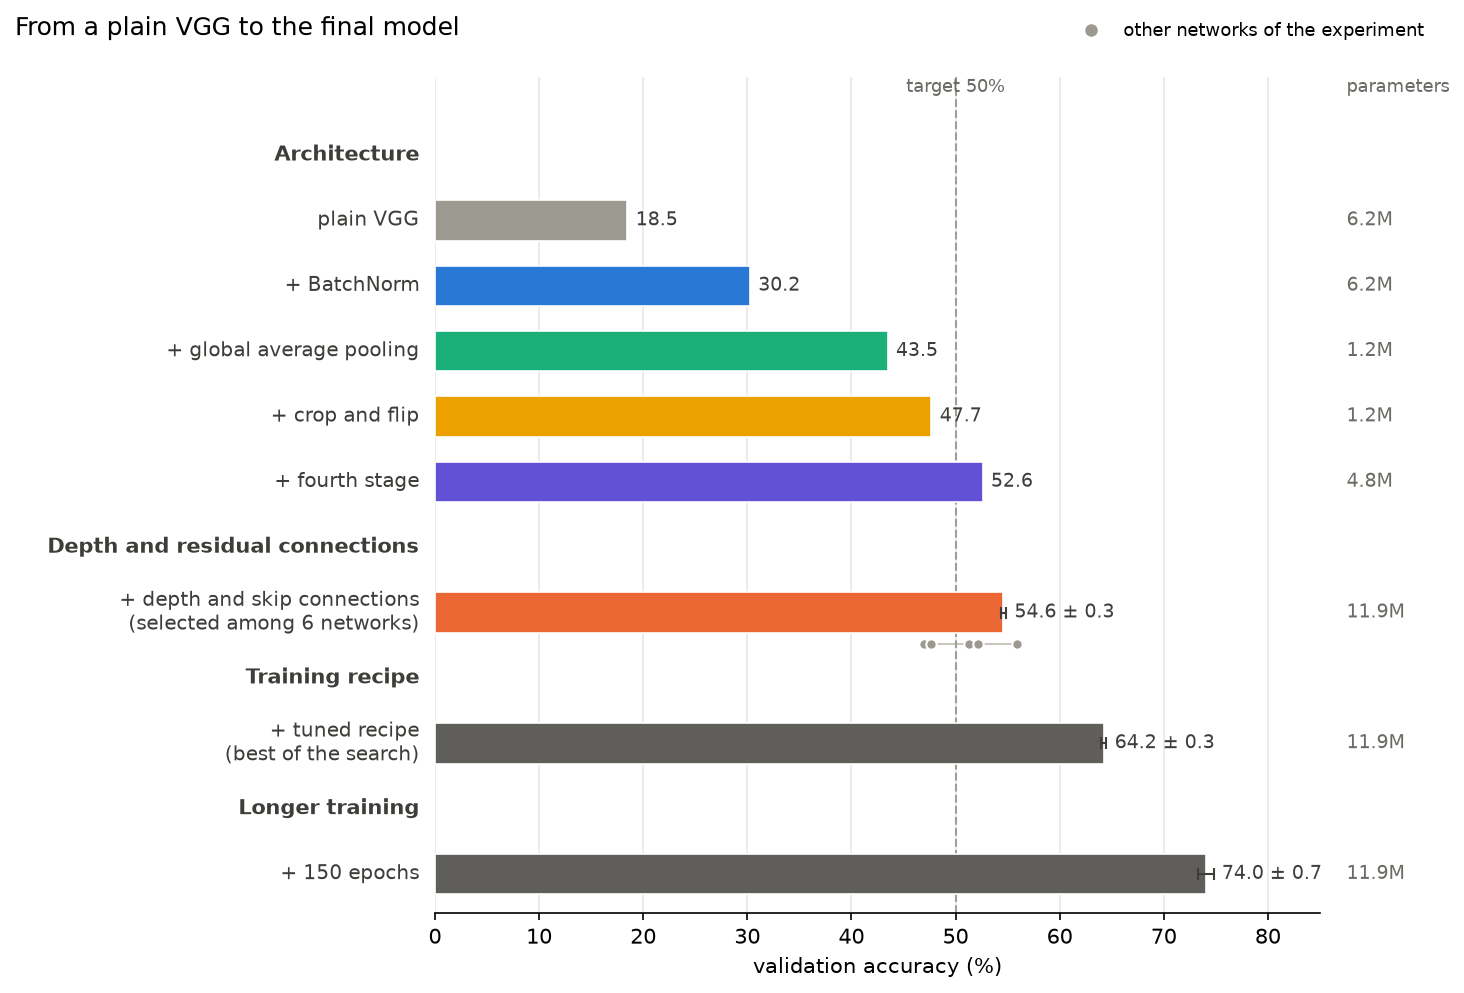

1. **Roadmap.** We start from a plain VGG-style network and add one design choice at a time (BatchNorm, global
   average pooling, augmentation, a fourth stage), so that every difference in accuracy has a single cause.
2. **Depth and residual connections.** On top of the last network of the roadmap (which happened to be the best), we compare plain and residual networks of increasing depth.
3. **Training recipe.** The three best networks receive the same hyperparameter search over the regularizers and the learning-rate schedule.
4. **Longer training.** The tuned networks are trained for 150 epochs instead of 70, and the final model is selected.
5. **Ablation.** Every component of the final model is removed in turn, to measure what it contributes.

All runs use 224×224 images, batch 64 and SGD with momentum 0.9. The roadmap and the depth experiment train every network for 70 epochs at three learning rates and keep the best, since different networks prefer different learning rates. The training recipe then tunes the learning rate together with the other hyperparameters, and the final model and its ablation are trained for 150 epochs. All choices are made on the validation split while the test accuracy is reported but never used to select anything.

**Result.** The final model is a residual network with 31 convolutional layers, trained for 150 epochs with the tuned recipe: **74.0% ± 0.7 validation and 74.2% ± 0.2 test accuracy** (mean ± standard deviation over three seeds).



## Setup (shared by all parts)

**How to run.** The notebook runs top to bottom, locally or on Colab, and needs no access to Google Drive. All the
runs reported below are stored in a shared Google Drive folder (a copy of the `results` directory) and the ones
missing from the local `results` directory are downloaded automatically with `gdown`: a run whose result already
exists with the same configuration is skipped, so the whole notebook, tables and plots included, reproduces our
results without training. Setting `RETRAIN = True` trains everything again. If the official dataset server is
unavailable, the same archive is downloaded from a Kaggle mirror; if that fails too, the cells that need the images
are skipped and the stored results are still loaded and shown. The images are read and preprocessed on the fly
(there is no cache), on the CPU. Locally, results are kept in the `results` directory of the repository and the
dataset in its `data` directory (git-ignored, created if missing); on Colab both stay on the temporary disk of the
session.

In [ ]:
%pip install -q torchinfo kagglehub gdown

/Users/alessandroteodori/code/100planes-X-IPCV/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import json
import math
import random
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchinfo
from torchvision import datasets
from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T
from torchvision.transforms import functional as TF
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

IN_COLAB = "google.colab" in sys.modules
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")

RETRAIN = False  # True: retrain runs even if their JSON already exists
print(f"device: {DEVICE}" + (f" ({torch.cuda.get_device_name()})" if DEVICE.type == "cuda" else "")
      + f" | torch {torch.__version__}")

device: mps | torch 2.14.1


/Users/alessandroteodori/code/100planes-X-IPCV/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Paths

Results and the dataset are kept in the repository (`results/`, `data/`) when the
notebook runs locally, and on the temporary disk of the session on Colab. The stored results of the project are then
downloaded with `gdown` from the shared Google Drive folder, which holds a copy of the `results` directory: only the
files that are not already there, and existing files are never overwritten.

In [ ]:
if IN_COLAB:
    RESULTS_ROOT = Path("/content/results")
    DATA_ROOT = Path("/content/data")
else:
    REPO_DIR = Path.cwd().parent if Path.cwd().name == "code" else Path.cwd()
    RESULTS_ROOT = REPO_DIR / "results"
    DATA_ROOT = REPO_DIR / "data"  # dataset: git-ignored, created if missing
RESULTS_DIR = RESULTS_ROOT / "part1"
RESULTS_DIR_2A = RESULTS_ROOT / "part2A"

for d in (RESULTS_DIR, RESULTS_DIR_2A, DATA_ROOT):
    d.mkdir(parents=True, exist_ok=True)
print("results ->", RESULTS_ROOT)

GDRIVE_FOLDER = "https://drive.google.com/drive/folders/1KfN4HcjaVCuXfqei8PaubVUVhffhJan2"  # copy of results/
FETCH_RESULTS = True  # False: use only the results already in RESULTS_ROOT


def fetch_results(folder_url, dest_root):
    # List the shared Google Drive folder (a copy of results/) and download with gdown the JSON files that are not in
    # dest_root yet, never overwriting an existing file.
    import gdown

    files = gdown.download_folder(
        url=folder_url, skip_download=True, quiet=True, use_cookies=False
    )
    added = kept = failed = 0
    last_error = None
    for f in tqdm(files, desc="results from Google Drive"):
        path = Path(f.path)
        if (
            path.suffix != ".json"
            or path.is_absolute()
            or ".." in path.parts
            or any(p.startswith(".") for p in path.parts)
        ):
            continue
        target = dest_root / path
        if target.exists():
            kept += 1
            continue
        target.parent.mkdir(parents=True, exist_ok=True)
        try:
            ok = (
                gdown.download(
                    id=f.id, output=str(target), quiet=True, use_cookies=False
                )
                is not None
            )
        except Exception as e:  # e.g. the daily download quota of the file is exceeded
            ok = False
            last_error = e
        failed += not ok
        added += ok
    print(
        f"results from Google Drive: {added} downloaded, {kept} already present"
        + (
            f", {failed} FAILED (rerun the cell to retry): {last_error}"
            if failed
            else ""
        )
    )


if FETCH_RESULTS:
    try:
        fetch_results(GDRIVE_FOLDER, RESULTS_ROOT)
    except Exception as e:
        print(
            f"WARNING: could not download the results from Google Drive ({e}); using the ones already in {RESULTS_ROOT}"
        )

results -> /Users/alessandroteodori/code/100planes-X-IPCV/results


results from Google Drive: 100%|██████████| 237/237 [00:00<00:00, 47751.84it/s]

results from Google Drive: 0 downloaded, 237 already present


### Reproducibility

We seed every source of randomness (initialization, data order, augmentation) and keep cuDNN deterministic, so that a
configuration trained twice with the same seed gives the same result. Training a configuration with different seeds
is how we measure run-to-run noise.

In [ ]:
def fix_random(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


fix_random(42)

## Configuration

A base configuration holds every choice shared by all runs; each experiment changes only what it studies.

- **Optimizer: SGD with momentum 0.9** — the optimizer of VGG and ResNet (lecture 3, *SGD with minibatches*; lecture 5).
- **Learning-rate sweep.** Each configuration is trained at learning rates 0.1, 0.05 and 0.01 (log-spaced, lecture 6 *Random
  hyper-parameters search*) and represented by its best one. The best learning rate depends on the network — without
  BatchNorm, or with a large classification head, training becomes unstable at values that a normalized network
  handles well — so a single value for every step could make a step look harmful only because the value does not
  suit it.
- **Schedule: linear warmup for 3 epochs, then cosine decay to zero** (lecture 6, *Learning rate schedule: cosine* and
  *warm-up*). A large learning rate makes fast progress but cannot settle into a minimum; decaying it lets the
  network settle, and starting low avoids large updates while the weights are still random.
- **Budget: 70 epochs, batch 64** — a compromise between convergence and the number of runs the study requires; the
  selected networks are trained longer at the end.
- **Resolution: 224x224**, the standard resolution of ImageNet training and of the pretrained ResNet-18 of Part 2.
- **Regularizers off** (weight decay, label smoothing, dropout, random erasing) until the training recipe, so that the
  roadmap and the depth experiment measure the architecture alone.

In [ ]:
BASE = dict(
    seed=42,
    # data
    img_size=224,
    augment=False,
    crop_scale=(0.5, 1.0),  # RandomResizedCrop: area of the crop, as a fraction of the image
    # architecture
    stem=(32, 32, 64),
    channels=(64, 128, 256),
    blocks=(1, 1, 1),  # blocks per stage; a block is two 3x3 convs
    batchnorm=False,
    gap=False,
    residual=False,
    dropout=0.0,  # before the classifier; searched in the training recipe
    # training
    epochs=70,
    batch_size=64,
    lr=0.05,  # overridden by the sweep
    momentum=0.9,
    weight_decay=0.0,  # searched in the training recipe
    label_smoothing=0.0,  # searched in the training recipe
    random_erasing=0.0,  # probability of erasing a random rectangle; searched in the training recipe
    warmup_epochs=3,
)

# every configuration is trained at each of these learning rates and represented by its best one (on validation)
LR_SWEEP = [0.1, 0.05, 0.01]

# extra seeds for the depth x residual networks and for the recipe (seed 42 comes from the sweep)
SEEDS = [42, 43, 44]

# The ladder: each step adds exactly one change on top of all the previous ones
STEPS = [
    ("s0_vgg", dict()),
    ("s1_bn", dict(batchnorm=True)),
    ("s2_gap", dict(gap=True)),
    ("s3_aug", dict(augment=True)),
    ("s4_stage4", dict(channels=(64, 128, 256, 512), blocks=(1, 1, 1, 1))),
]


def cumulative(steps):
    # [(name, overrides of that step and of all the steps before it)]
    acc, out = {}, []
    for name, change in steps:
        acc = {**acc, **change}
        out.append((name, dict(acc)))
    return out


LADDER = cumulative(STEPS)
S4 = LADDER[-1][1]

# Depth x residual, on top of s4: three depths, each with and without skip connections (see the section for why)
GRID = [
    ("plain_1111", dict(S4, blocks=(1, 1, 1, 1), residual=False)),  # = s4
    ("res_1111", dict(S4, blocks=(1, 1, 1, 1), residual=True)),
    ("plain_2222", dict(S4, blocks=(2, 2, 2, 2), residual=False)),  # ResNet-18 layout
    ("res_2222", dict(S4, blocks=(2, 2, 2, 2), residual=True)),
    ("plain_3461", dict(S4, blocks=(3, 4, 6, 1), residual=False)),  # ResNet-34 layout, one 512-block
    ("res_3461", dict(S4, blocks=(3, 4, 6, 1), residual=True)),
]

# The regularizers of the training recipe, at the values they keep during step 1 of its search (lr x weight decay)
RECIPE = dict(weight_decay=5e-4, label_smoothing=0.1, dropout=0.2, random_erasing=0.25)

# Recipe tuning (see its section): the TUNE_N best networks of the grid get the same search
TUNE_N = 3
TUNE_LRS = [0.1, 0.05]  # grid search: learning rate x weight decay (log-spaced)
TUNE_WDS = [1e-4, 5e-4, 1e-3, 2e-3, 5e-3, 1e-2]
SEARCH_SPACE = dict(  # random search over the other recipe parameters
    label_smoothing=[0.0, 0.05, 0.1, 0.2],
    dropout=[0.0, 0.2, 0.5],
    random_erasing=[0.0, 0.25, 0.5],
    crop_scale=[(0.25, 1.0), (0.35, 1.0), (0.5, 1.0)],
    schedule=["cosine", "onecycle"],
)
N_RANDOM = 12  # random configurations, the same list for every network
SEARCH_SEED = 0  # seed of the random draw of the configurations (not of the trainings)
TOP_K = 2  # best configurations of each network confirmed with the other seeds

# Longer training: the tuned networks, each with its best configuration, trained for more epochs
LONG_EPOCHS = 150

s0_vgg       {}
s1_bn        {'batchnorm': True}
s2_gap       {'batchnorm': True, 'gap': True}
s3_aug       {'batchnorm': True, 'gap': True, 'augment': True}
s4_stage4    {'batchnorm': True, 'gap': True, 'augment': True, 'channels': (64, 128, 256, 512), 'blocks': (1, 1, 1, 1)}
plain_1111   {'batchnorm': True, 'gap': True, 'augment': True, 'channels': (64, 128, 256, 512), 'blocks': (1, 1, 1, 1), 'residual': False}
res_1111     {'batchnorm': True, 'gap': True, 'augment': True, 'channels': (64, 128, 256, 512), 'blocks': (1, 1, 1, 1), 'residual': True}
plain_2222   {'batchnorm': True, 'gap': True, 'augment': True, 'channels': (64, 128, 256, 512), 'blocks': (2, 2, 2, 2), 'residual': False}
res_2222     {'batchnorm': True, 'gap': True, 'augment': True, 'channels': (64, 128, 256, 512), 'blocks': (2, 2, 2, 2), 'residual': True}
plain_3461   {'batchnorm': True, 'gap': True, 'augment': True, 'channels': (64, 128, 256, 512), 'blocks': (3, 4, 6, 1), 'residual': False}
res_3461     {'batchnorm': Tr

## Data

FGVC-Aircraft (`torchvision.datasets.FGVCAircraft`, `annotation_level="variant"`) has 100 classes and 3,334 / 3,333 / 3,333 images in the training / validation / test splits: about **33 training images per class**. With so few images a network can memorize the training set long before it learns features that generalize, and this is the problem most of the following steps address.

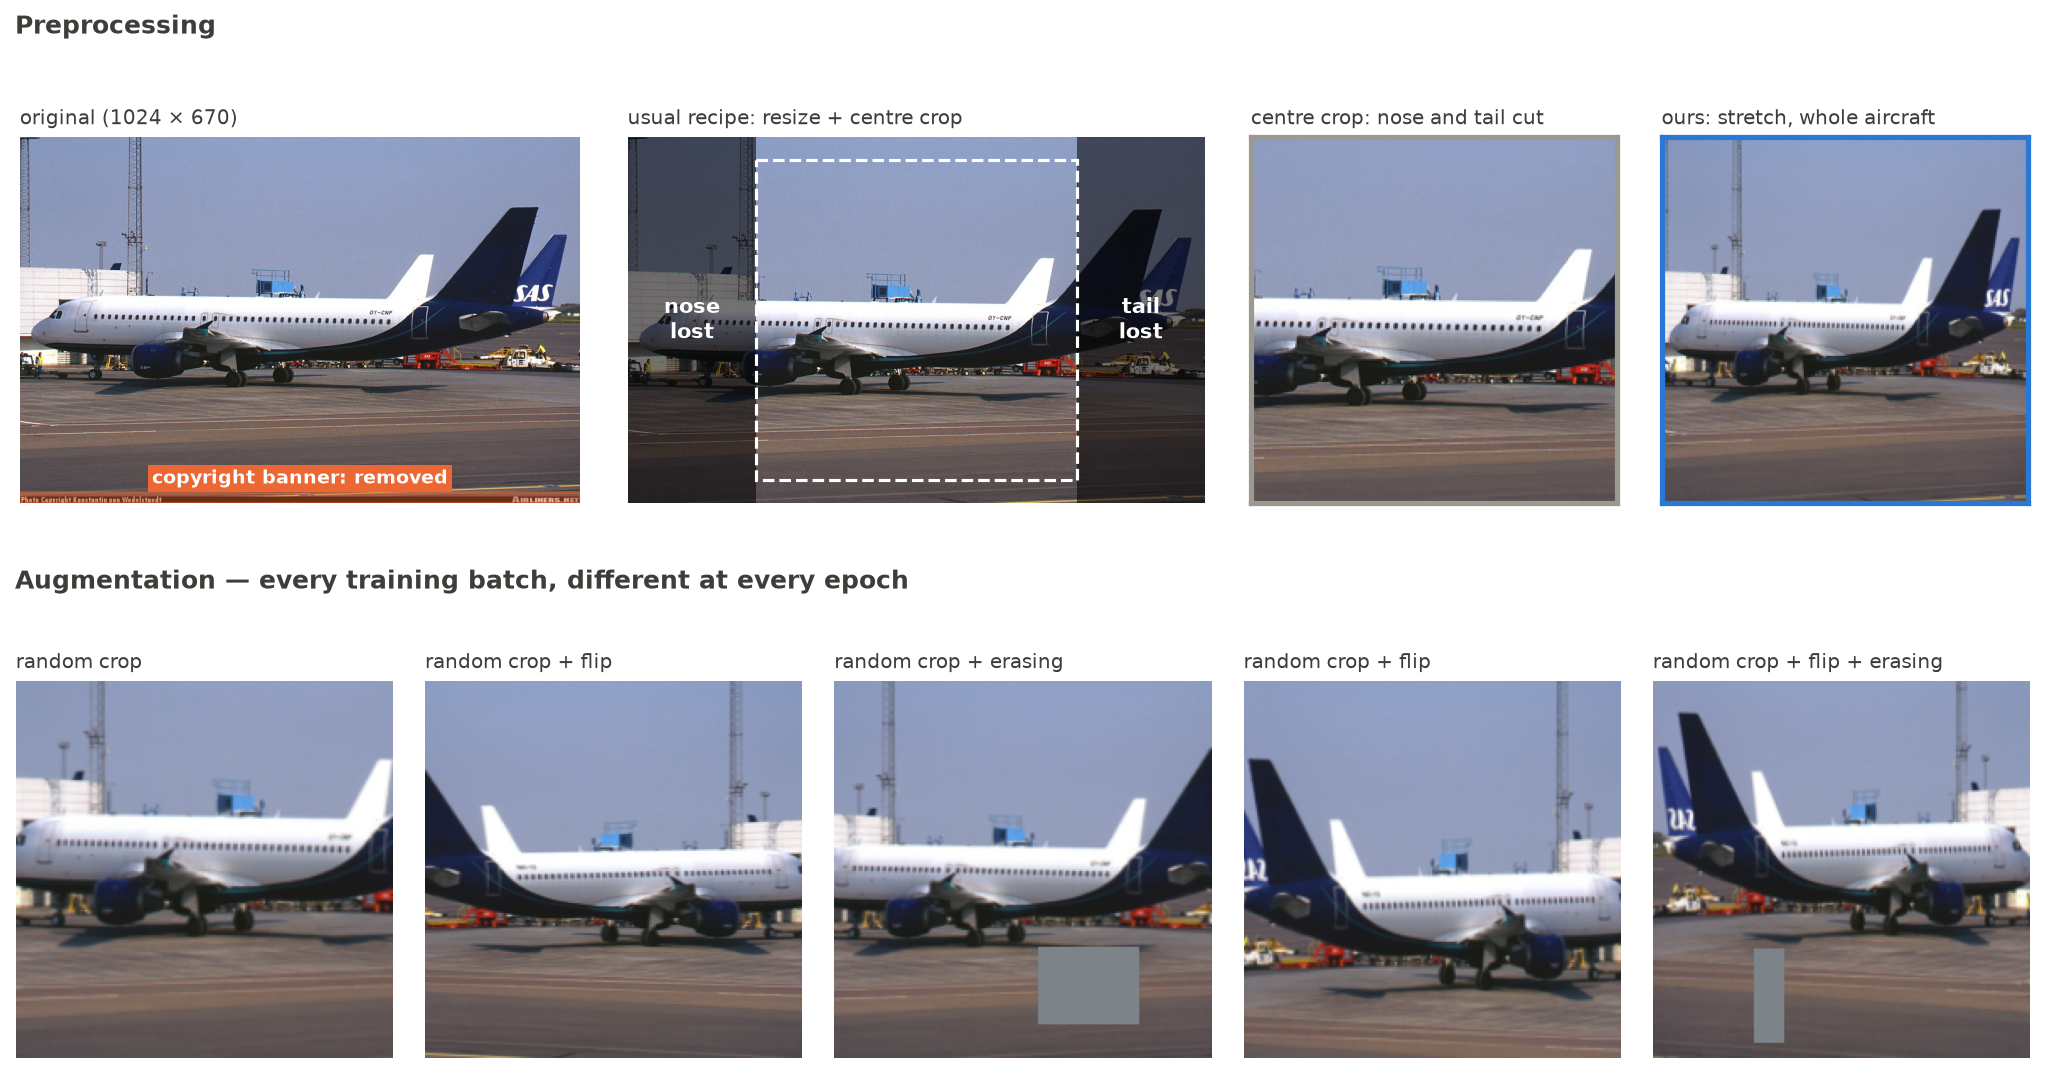

**Preprocessing** (top row). As the authors of the dataset require, we remove the 20-pixel copyright banner at the bottom of every image ("Please make sure to remove this banner when using the images to train and evaluate algorithms", <a href="https://www.robots.ox.ac.uk/~vgg/data/fgvc-aircraft/#format" target="_blank">FGVC-Aircraft</a>
). We then and resize the image to 224x224 *without* keeping the aspect ratio. Normalization uses the per-channel mean and standard deviation of the training split only (the pretrained network of Part 2 is the exception: it expects the statistics of ImageNet).

**Augmentation, on training batches only** (bottom row; lecture 6, *Data augmentation*). Random resized crops and horizontal flips change scale and position while preserving the label: a mirrored aircraft is still the same aircraft. Then random erasing is added by the training recipe.

**Data loading.** The images are read and preprocessed on the fly by a `DataLoader`; the augmentation uses the
torchvision transforms `RandomResizedCrop`, `RandomHorizontalFlip` and `RandomErasing`. The dataset is always loaded
through the torchvision class; when its official server is unavailable, the identical `fgvc-aircraft-2013b` archive is
downloaded from a public Kaggle mirror and placed where the class expects it.

In [ ]:
from functools import cache

BANNER_PX = 20
KAGGLE_MIRROR = "seryouxblaster764/fgvc-aircraft"  # public copy of the official fgvc-aircraft-2013b archive
IMAGENET_MEAN, IMAGENET_STD = (
    (0.485, 0.456, 0.406),
    (0.229, 0.224, 0.225),
)  # statistics the pretrained ResNet-18 expects


def fetch_from_kaggle(root):
    # Download the official archive from the Kaggle mirror and place it where torchvision's FGVCAircraft expects it.
    import kagglehub

    path = Path(kagglehub.dataset_download(KAGGLE_MIRROR))
    source = next(
        (
            p
            for p in [path, *path.rglob("fgvc-aircraft-2013b")]
            if (p / "data" / "images").is_dir()
        ),
        None,
    )
    if source is None:
        raise RuntimeError(f"unexpected layout of the Kaggle mirror in {path}")
    target = root / "fgvc-aircraft-2013b"
    root.mkdir(parents=True, exist_ok=True)
    if target.is_symlink() or target.exists():
        if (target / "data" / "images").is_dir():
            return
        raise RuntimeError(
            f"{target} exists but is incomplete: remove it and run again"
        )
    target.symlink_to(source, target_is_directory=True)


NUM_WORKERS = 4 if IN_COLAB else 0   # DataLoader workers; 0 locally (notebook classes cannot be pickled by spawn)


@cache
def load_split(split):
    # The torchvision dataset of one split, downloaded if needed.
    try:
        return datasets.FGVCAircraft(
            DATA_ROOT, split=split, annotation_level="variant", download=True
        )
    except Exception as official_error:
        # the official server is sometimes unavailable: same archive from the Kaggle mirror, still read by torchvision
        print(
            f"official download failed ({official_error}): using the Kaggle mirror {KAGGLE_MIRROR}"
        )
        try:
            fetch_from_kaggle(DATA_ROOT)
            return datasets.FGVCAircraft(
                DATA_ROOT, split=split, annotation_level="variant", download=True
            )
        except Exception as e:
            raise RuntimeError(
                f"could not download FGVC-Aircraft, neither from the official server "
                f"({official_error}) nor from Kaggle ({e})"
            ) from e


def preprocess(img, img_size):
    # Crop the copyright banner and stretch the image to a square.
    img = img.crop((0, 0, img.width, img.height - BANNER_PX))
    return TF.resize(img, [img_size, img_size], antialias=True)


class AircraftSplit(Dataset):
    # One split read on the fly: preprocessed image -> transform -> (tensor, label).
    def __init__(self, split, img_size, transform):
        self.base, self.img_size, self.transform = load_split(split), img_size, transform
        self.split, self.classes = split, self.base.classes
        self.y = torch.tensor(self.base._labels)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        img, label = self.base[i]
        return self.transform(preprocess(img, self.img_size)), label

    def with_transform(self, transform):
        return AircraftSplit(self.split, self.img_size, transform)


@cache
def train_statistics(img_size):
    # Per-channel mean and standard deviation over every pixel of the training split.
    loader = DataLoader(AircraftSplit("train", img_size, T.ToTensor()), batch_size=256, num_workers=NUM_WORKERS)
    total, total_sq, n = torch.zeros(3, dtype=torch.float64), torch.zeros(3, dtype=torch.float64), 0
    for x, _ in tqdm(loader, desc="statistics of the training split"):
        x = x.double()
        total += x.sum(dim=(0, 2, 3))
        total_sq += (x**2).sum(dim=(0, 2, 3))
        n += x.shape[0] * x.shape[2] * x.shape[3]
    mean = total / n
    std = (total_sq / n - mean**2).sqrt()
    return tuple(mean.tolist()), tuple(std.tolist())


_DATA = {}


def get_data(img_size, imagenet_stats=False):
    # The three splits at one resolution, plus normalization statistics: measured on train only, or those of
    # ImageNet for the pretrained network. The splits are read with the evaluation transform (no augmentation).
    key = (img_size, imagenet_stats)
    if key not in _DATA:
        mean, std = (IMAGENET_MEAN, IMAGENET_STD) if imagenet_stats else train_statistics(img_size)
        evaluation = T.Compose([T.ToTensor(), T.Normalize(mean, std)])
        splits = {s: AircraftSplit(s, img_size, evaluation) for s in ("train", "val", "test")}
        _DATA[key] = dict(splits, mean=mean, std=std)
    return _DATA[key]


def train_transform(data, cfg):
    # Augmentation of the training images: random resized crop + flip (cfg["augment"]), random erasing.
    steps = []
    if cfg["augment"]:
        steps += [
            T.RandomResizedCrop(cfg["img_size"], scale=tuple(cfg["crop_scale"]), ratio=(3 / 4, 4 / 3), antialias=True),
            T.RandomHorizontalFlip(),
        ]
    steps += [T.ToTensor(), T.Normalize(data["mean"], data["std"])]
    if cfg["random_erasing"] > 0:
        steps.append(T.RandomErasing(p=cfg["random_erasing"], value=0))  # 0 is the mean of the normalized images
    return T.Compose(steps)


def batches(split, data, cfg, train):
    # Yields normalized (x, y) batches; train=True shuffles, drops the last partial batch and augments.
    if train:
        split = split.with_transform(train_transform(data, cfg))
    loader = DataLoader(
        split, batch_size=cfg["batch_size"] if train else 512, shuffle=train, drop_last=train, num_workers=NUM_WORKERS
    )
    for x, y in loader:
        yield x.to(DEVICE), y.to(DEVICE)

In [ ]:
try:
    data = get_data(BASE["img_size"])
except Exception as e:
    data = None
    print(
        f"WARNING: the dataset is not available ({e})\n"
        "The cells that need the images are skipped; the stored results are still loaded and shown."
    )

N_CLASSES = 100  # FGVC-Aircraft, annotation_level="variant"
if data is not None:
    CLASSES = data["train"].classes
    assert len(CLASSES) == N_CLASSES
    print(
        f"classes: {N_CLASSES} | train {len(data['train'])} | val {len(data['val'])} | test {len(data['test'])}"
    )

100%|██████████| 2.75G/2.75G [00:32<00:00, 85.9MB/s]


caching train @ 224px:   0%|          | 0/3334 [00:00<?, ?it/s]

caching val @ 224px:   0%|          | 0/3333 [00:00<?, ?it/s]

caching test @ 224px:   0%|          | 0/3333 [00:00<?, ?it/s]

classes: 100 | train 3334 | val 3333 | test 3333


## The network

A single network class builds every network of the study from its configuration. In the figure, the components
added by a step of the roadmap have the colour of that step in the roadmap chart; $n_1, \dots, n_4$ are the
numbers of blocks per stage, varied in section 2:

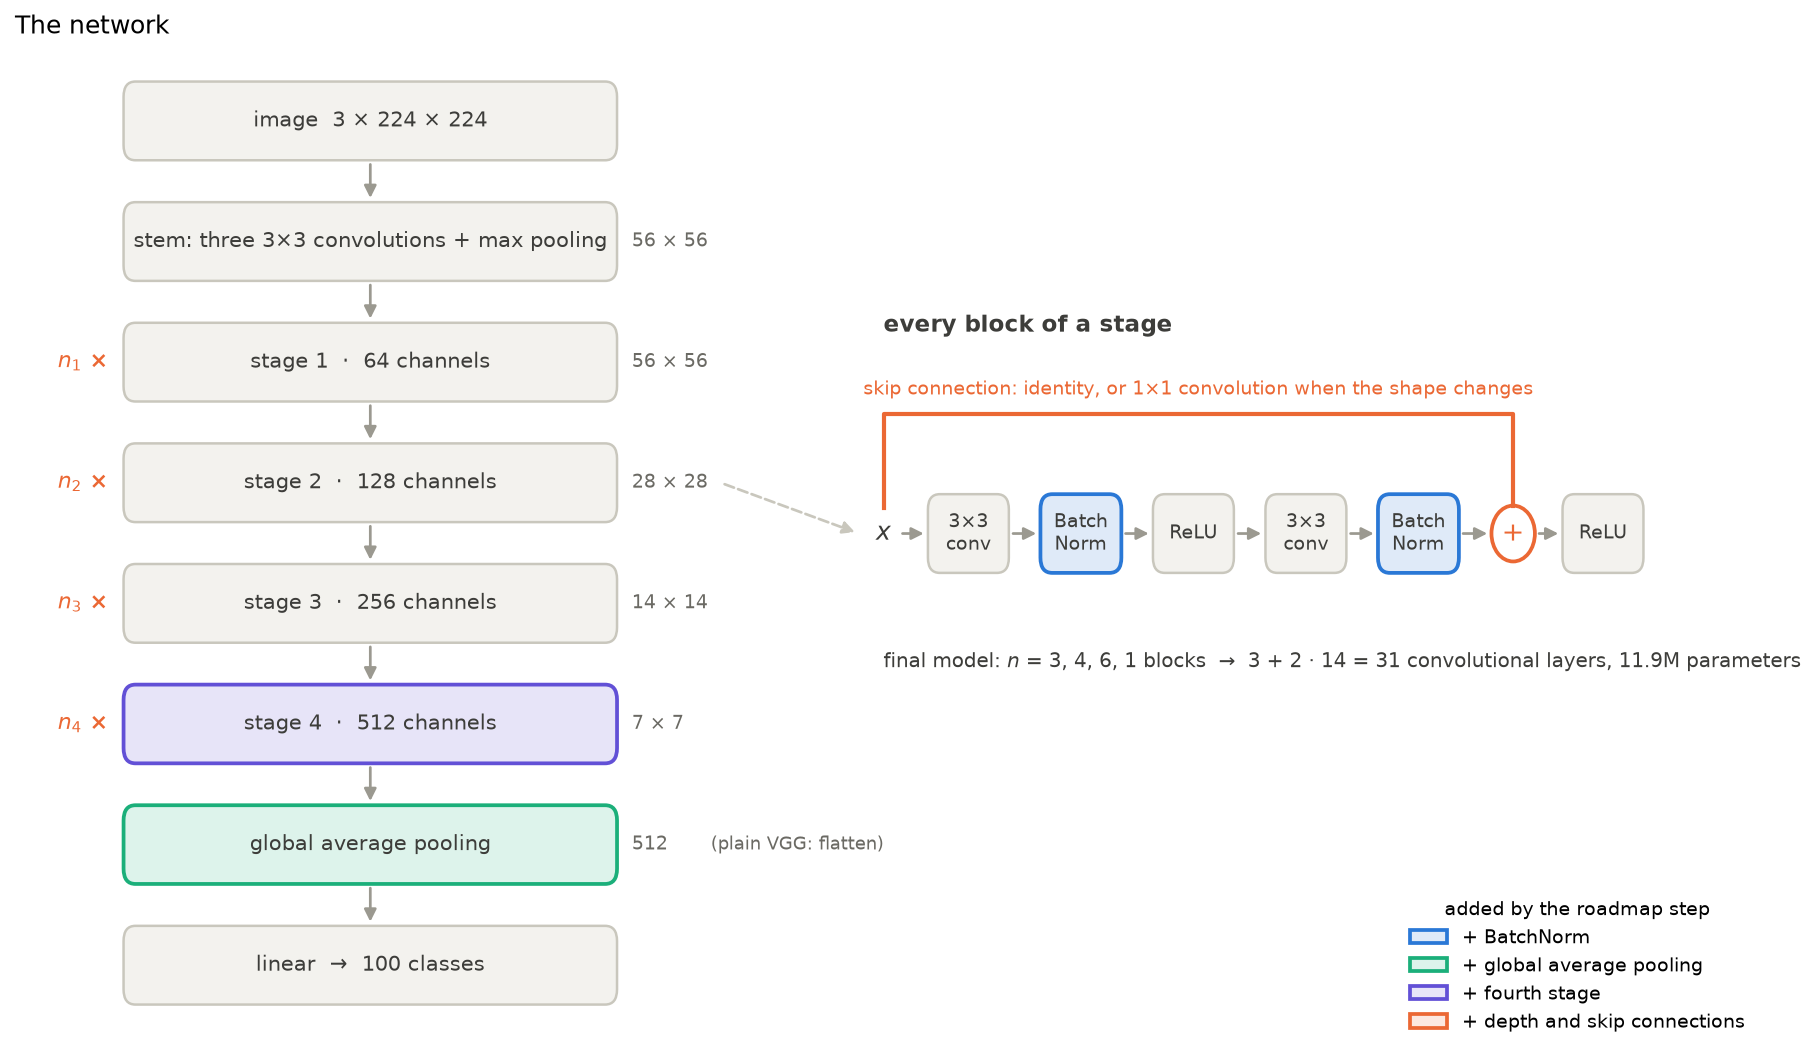

- **Stages** (lecture 5, *VGG: deep but regular*, *Stages*). The network is a stem followed by stages of identical blocks;
  every stage after the first halves the resolution and doubles the channels. A block is two 3x3 convolutions, which
  cover the receptive field of a 5x5 convolution with fewer parameters and one more non-linearity.
- **Stem** (lecture 5, *Stem layers*; *Further model tweaks — ResNet-C*). The resolution is reduced by 4 before the first
  stage, as in ResNet and GoogLeNet, since early layers detect simple patterns that need no full resolution and the
  blocks are 16 times cheaper at 56x56 than at 224x224. As in ResNet-C, the 7x7 convolution of ResNet is replaced by
  three 3x3 convolutions (32, 32, 64 channels), the first one with stride 2.
- **BatchNorm** (lecture 4, *Batch Norm*; Ioffe & Szegedy, 2015) normalizes the activations of each channel over the batch.
  It allows higher learning rates and makes initialization less critical. It is placed after every convolution,
  before the ReLU, and the convolutions it follows have no bias.
- **Global average pooling** (lecture 5, *Fully-connected classifier vs global average pooling*; Lin et al., 2014) averages
  each channel of the last feature map, replacing a flatten layer whose classifier would hold most of the parameters
  of the network.
- **Residual connections** (lecture 5, *Residual Networks*, *Residual block*, *Skip conn dimensions*; He et al., 2016).
  The block computes $F(x) + x$: it only has to learn a correction of the identity, and very deep networks become
  trainable. When a block changes resolution or channels, the input goes through a 1x1 convolution with BatchNorm
  (projection); otherwise it is added unchanged. Plain networks do not create the projections, so plain and residual
  versions of a network have almost the same number of parameters.
- **Initialization:** Kaiming normal (He et al., 2015), which keeps the scale of the activations stable through depth.

In [ ]:
def conv_bn(c_in, c_out, k, stride, bn):
    layers = [nn.Conv2d(c_in, c_out, k, stride=stride, padding=k // 2, bias=not bn)]
    if bn:
        layers.append(nn.BatchNorm2d(c_out))
    return nn.Sequential(*layers)


class Block(nn.Module):
    def __init__(self, c_in, c_out, stride, bn, residual):
        super().__init__()
        self.conv1 = conv_bn(c_in, c_out, 3, stride, bn)
        self.conv2 = conv_bn(c_out, c_out, 3, 1, bn)
        self.residual = residual
        if residual and (stride != 1 or c_in != c_out):
            self.skip = conv_bn(c_in, c_out, 1, stride, bn)  # projection
        else:
            self.skip = nn.Identity()

    def forward(self, x):
        out = self.conv2(F.relu(self.conv1(x)))
        if self.residual:
            out = out + self.skip(x)
        return F.relu(out)


class AircraftNet(nn.Module):
    def __init__(self, cfg, n_classes=100):
        super().__init__()
        bn = cfg["batchnorm"]
        c1, c2, c3 = cfg["stem"]
        self.stem = nn.Sequential(
            conv_bn(3, c1, 3, 2, bn),
            nn.ReLU(inplace=True),
            conv_bn(c1, c2, 3, 1, bn),
            nn.ReLU(inplace=True),
            conv_bn(c2, c3, 3, 1, bn),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(3, stride=2, padding=1),
        )
        layers, c_in = [], c3
        for stage, (c_out, n_blocks) in enumerate(zip(cfg["channels"], cfg["blocks"])):
            for b in range(n_blocks):
                stride = 2 if (b == 0 and stage > 0) else 1
                layers.append(Block(c_in, c_out, stride, bn, cfg["residual"]))
                c_in = c_out
        self.stages = nn.Sequential(*layers)

        if cfg["gap"]:
            self.head = nn.Sequential(
                nn.AdaptiveAvgPool2d(1),
                nn.Flatten(),
                nn.Dropout(cfg["dropout"]),
                nn.Linear(c_in, n_classes),
            )
        else:
            with torch.no_grad():  # size of the last feature map, for the flatten head
                s = self.stages(
                    self.stem(torch.zeros(1, 3, cfg["img_size"], cfg["img_size"]))
                ).shape
            self.head = nn.Sequential(
                nn.Flatten(),
                nn.Dropout(cfg["dropout"]),
                nn.Linear(s[1] * s[2] * s[3], n_classes),
            )

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.head(self.stages(self.stem(x)))


def build_model(cfg, n_classes=100):
    # The network of a configuration: our AircraftNet, or (Part 2) the ResNet-18 of PyTorch pretrained on ImageNet-1K
    # with its 1000-way classifier replaced by Dropout -> Linear(512, n_classes).
    if not cfg.get("pretrained", False):
        return AircraftNet(cfg, n_classes)
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Sequential(
        nn.Dropout(cfg["dropout"]), nn.Linear(model.fc.in_features, n_classes)
    )
    return model


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def count_gflops(model, img_size):
    # Multiply-adds of convolutions and linear layers for one image, x2 = FLOPs.
    macs = 0

    def hook(m, inp, out):
        nonlocal macs
        if isinstance(m, nn.Conv2d):
            macs += (
                out[0].numel()
                * (m.in_channels // m.groups)
                * m.kernel_size[0]
                * m.kernel_size[1]
            )
        elif isinstance(m, nn.Linear):
            macs += m.in_features * m.out_features

    handles = [
        m.register_forward_hook(hook)
        for m in model.modules()
        if isinstance(m, (nn.Conv2d, nn.Linear))
    ]
    with torch.no_grad():
        model.eval()(torch.zeros(1, 3, img_size, img_size))
    for h in handles:
        h.remove()
    return 2 * macs / 1e9

Layer-by-layer summary of one network (`torchinfo`).

In [ ]:
# the keys that only describe AircraftNet: a pretrained run does not store them
SCRATCH_ONLY_KEYS = ("stem", "channels", "blocks", "batchnorm", "gap", "residual")

torchinfo.summary(
    AircraftNet({**BASE, **dict(GRID)["res_2222"]}, N_CLASSES),
    input_size=(1, 3, BASE["img_size"], BASE["img_size"]),
    col_names=("output_size", "num_params"),
    row_settings=("var_names",),
    depth=4,
    device="cpu",
    verbose=0,
)

Layer (type (var_name))                  Output Shape              Param #
AircraftNet (AircraftNet)                [1, 100]                  --
├─Sequential (stem)                      [1, 64, 56, 56]           --
│    └─Sequential (0)                    [1, 32, 112, 112]         --
│    │    └─Conv2d (0)                   [1, 32, 112, 112]         864
│    │    └─BatchNorm2d (1)              [1, 32, 112, 112]         64
│    └─ReLU (1)                          [1, 32, 112, 112]         --
│    └─Sequential (2)                    [1, 32, 112, 112]         --
│    │    └─Conv2d (0)                   [1, 32, 112, 112]         9,216
│    │    └─BatchNorm2d (1)              [1, 32, 112, 112]         64
│    └─ReLU (3)                          [1, 32, 112, 112]         --
│    └─Sequential (4)                    [1, 64, 112, 112]         --
│    │    └─Conv2d (0)                   [1, 64, 112, 112]         18,432
│    │    └─BatchNorm2d (1)              [1, 64, 112, 112]         128
│    └

Size and cost of every network of the study. With the flatten classifier (the plain VGG and the network with
BatchNorm), the classifier alone holds 81% of the parameters.

In [ ]:
rows = []
for name, over in LADDER + GRID:
    cfg = {**BASE, **over}
    m = AircraftNet(cfg, N_CLASSES)
    head = sum(p.numel() for p in m.head.parameters())
    rows.append(
        dict(
            run=name,
            params_M=count_params(m) / 1e6,
            head_share=head / count_params(m),
            GFLOPs=count_gflops(m, cfg["img_size"]),
            convs=sum(isinstance(l, nn.Conv2d) for l in m.modules()),
        )
    )
pd.DataFrame(rows).set_index("run").style.format(
    {"params_M": "{:.2f}", "head_share": "{:.0%}", "GFLOPs": "{:.2f}"}
)

,params_M,head_share,GFLOPs,convs
run,,,,
s0_vgg,6.23,81%,1.88,9
s1_bn,6.23,81%,1.88,9
s2_gap,1.24,2%,1.87,9
s3_aug,1.24,2%,1.87,9
s4_stage4,4.80,1%,2.22,11
plain_1111,4.80,1%,2.22,11
res_1111,4.98,1%,2.26,14
plain_2222,11.07,0%,4.07,19
res_2222,11.25,0%,4.11,22


## Training

- **Loss:** cross-entropy (lecture 3, *Softmax function*, *Cross-entropy loss*), with label smoothing where the recipe enables
  it. The validation loss is always the plain cross-entropy, so that all curves share the same scale.
- **Weight decay**, when enabled, applies to convolution and linear weights only, not to BatchNorm parameters and
  biases.
- **Model selection** (lecture 6, *Early stopping*): every run keeps the epoch with the highest validation accuracy, and the
  test split is evaluated once, on that checkpoint.

In [ ]:
def make_optimizer(model, cfg):
    decay = [p for p in model.parameters() if p.ndim > 1]
    no_decay = [p for p in model.parameters() if p.ndim <= 1]
    return torch.optim.SGD(
        [
            {"params": decay, "weight_decay": cfg["weight_decay"]},
            {"params": no_decay, "weight_decay": 0.0},
        ],
        lr=cfg["lr"],
        momentum=cfg["momentum"],
    )


def lr_at(epoch, cfg):
    if cfg.get("schedule", "cosine") == "onecycle":
        # one-cycle (Smith & Topin, 2019), per epoch: cosine rise from lr/25 to lr over the first 30% of the
        # epochs, then cosine decay to lr/1e4 (the defaults of torch.optim.lr_scheduler.OneCycleLR)
        up = max(round(0.3 * cfg["epochs"]), 1)
        low, high, end = cfg["lr"] / 25, cfg["lr"], cfg["lr"] / 1e4
        if epoch < up:
            return high + (low - high) * (1 + math.cos(math.pi * epoch / up)) / 2
        t = (epoch - up) / max(cfg["epochs"] - up, 1)
        return end + (high - end) * (1 + math.cos(math.pi * t)) / 2
    if epoch < cfg["warmup_epochs"]:
        return cfg["lr"] * (epoch + 1) / cfg["warmup_epochs"]
    progress = (epoch - cfg["warmup_epochs"]) / max(
        cfg["epochs"] - cfg["warmup_epochs"], 1
    )
    return cfg["lr"] * 0.5 * (1 + math.cos(math.pi * progress))


def train_epoch(model, opt, criterion, data, cfg):
    model.train()
    total_loss = torch.zeros((), device=DEVICE)
    correct = torch.zeros((), device=DEVICE)
    n = 0
    for x, y in batches(data["train"], data, cfg, train=True):
        logits = model(x)
        loss = criterion(logits, y)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        total_loss += loss.detach().float() * len(y)
        correct += (logits.argmax(1) == y).sum()
        n += len(y)
    return total_loss.item() / n, correct.item() / n


@torch.no_grad()
def evaluate(model, split, data, cfg, return_preds=False):
    model.eval()
    total_loss, correct, preds = 0.0, 0, []
    for x, y in batches(split, data, cfg, train=False):
        logits = model(x)
        total_loss += F.cross_entropy(logits, y, reduction="sum").item()
        p = logits.argmax(1)
        correct += (p == y).sum().item()
        if return_preds:
            preds.append(p.cpu())
    n = len(split)
    out = (total_loss / n, correct / n)
    return out + (torch.cat(preds).tolist(),) if return_preds else out


def fit(cfg, data, verbose=True):
    model = build_model(cfg, N_CLASSES).to(DEVICE)
    opt = make_optimizer(model, cfg)
    criterion = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])
    hist = {
        k: []
        for k in ("train_loss", "train_acc", "val_loss", "val_acc", "lr", "seconds")
    }
    best_acc, best_epoch, best_state, diverged = -1.0, 0, None, False

    for epoch in range(cfg["epochs"]):
        t0 = time.time()
        lr = lr_at(epoch, cfg)
        for g in opt.param_groups:
            g["lr"] = lr
        tr_loss, tr_acc = train_epoch(model, opt, criterion, data, cfg)
        if not math.isfinite(tr_loss):
            diverged = True
            print(f"  diverged at epoch {epoch + 1} (training loss {tr_loss})")
            break
        va_loss, va_acc = evaluate(model, data["val"], data, cfg)
        for k, v in zip(hist, (tr_loss, tr_acc, va_loss, va_acc, lr, time.time() - t0)):
            hist[k].append(v)
        if va_acc > best_acc:
            best_acc, best_epoch = va_acc, epoch + 1
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if verbose and (epoch % 5 == 0 or epoch == cfg["epochs"] - 1):
            print(
                f"  ep {epoch + 1:3d} | lr {lr:.4f} | train loss {tr_loss:.3f} acc {tr_acc:.3f} "
                f"| val loss {va_loss:.3f} acc {va_acc:.3f} | {hist['seconds'][-1]:.1f}s"
            )

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, hist, best_epoch, diverged

### Sanity checks

Before trusting any experiment we verify the training pipeline (lecture 6, *A "recipe" for training NNs*, step 2: "check
init loss, overfit a small dataset"). At initialization the loss must be close to ln(100) ≈ 4.61, the loss of a
uniform guess over 100 classes; and the network must be able to memorize 100 training images. A failure would point
to a bug in the data, the labels or the training step.

In [ ]:
if data is None:
    print("skipped: the dataset is not available")
else:
    fix_random(0)
    cfg = {**BASE, "batchnorm": True}
    model = AircraftNet(cfg, N_CLASSES).to(DEVICE)
    x, y = next(batches(data["train"], data, cfg, train=True))
    with torch.no_grad():
        print(
            f"initial loss {F.cross_entropy(model(x), y).item():.3f}  (expected ~{math.log(N_CLASSES):.2f})"
        )

    # memorize 100 images with Adam, full batch
    x = torch.stack([data["train"][i][0] for i in range(100)]).to(DEVICE)
    y = data["train"].y[:100].to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    model.train()
    for step in range(150):
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad()
        loss.backward()
        opt.step()
    model.eval()
    with torch.no_grad():
        print(
            f"tiny subset: train acc {(model(x).argmax(1) == y).float().mean().item():.2f}  (expected ~1.00)"
        )

initial loss 4.716  (expected ~4.61)
tiny subset: train acc 1.00  (expected ~1.00)


## Experiment runner

The runner trains one configuration (in `results/part1`, or in the directory given by `results_dir` for Part 2), evaluates its best checkpoint on the test split and stores the configuration,
the per-epoch curves and the test predictions; a run whose result already exists with the same configuration is
loaded instead of trained. Every configuration is first trained at the three learning rates (seed 42), then with two
more seeds at its best learning rate when the experiment requires it. The seed-42 result is the best of three learning
rates, hence slightly optimistic; the two other seeds are not. The plotting helpers used in the rest of the notebook
follow.

In [ ]:
def result_path(name, group, seed, results_dir=None):
    return (results_dir or RESULTS_DIR) / group / f"{name}_seed{seed}.json"


_LOADED = 0  # stored runs loaded since the last report_runs()


def report_runs():
    # One line instead of one per stored run: how many runs the previous cell loaded instead of training.
    global _LOADED
    if _LOADED:
        print(f"{_LOADED} stored runs loaded (same configuration, not retrained)")
    _LOADED = 0


def run_experiment(name, group, note="", results_dir=None, **overrides):
    global _LOADED
    cfg = {**BASE, **overrides, "name": name, "group": group}
    if cfg.get("pretrained", False):  # the architecture keys of AircraftNet do not describe the pretrained ResNet-18
        cfg = {k: v for k, v in cfg.items() if k not in SCRATCH_ONLY_KEYS}
    out = result_path(name, group, cfg["seed"], results_dir)
    if out.exists() and not RETRAIN:
        run = json.loads(out.read_text())
        if run["config"] == json.loads(json.dumps(cfg)):  # same configuration (tuples stored as lists)
            _LOADED += 1
            return run
        print(f"{group}/{name}: configuration changed since the stored run, training again")

    shown = ("lr", "weight_decay", "label_smoothing", "dropout", "random_erasing", "augment", "crop_scale", "seed", "epochs")
    print(f"### {group}/{name}\n    " + " | ".join(f"{k} {cfg[k]}" for k in shown)
          + f" | schedule {cfg.get('schedule', 'cosine')}")
    fix_random(cfg["seed"])
    data = get_data(cfg["img_size"], cfg.get("pretrained", False))
    t0 = time.time()
    model, hist, best_epoch, diverged = fit(cfg, data)
    minutes = (time.time() - t0) / 60
    if best_epoch:
        test_loss, test_acc, test_pred = evaluate(model, data["test"], data, cfg, return_preds=True)
    else:  # diverged before the first validation: there is no checkpoint to test
        test_loss, test_acc, test_pred = float("nan"), float("nan"), []

    cpu_model = build_model(cfg, N_CLASSES)
    run = dict(
        name=name, group=group, seed=cfg["seed"], note=note, config=cfg, history=hist,
        best_val_acc=max(hist["val_acc"], default=0.0), best_epoch=best_epoch,
        final_val_acc=hist["val_acc"][-1] if hist["val_acc"] else 0.0,
        final_train_acc=hist["train_acc"][-1] if hist["train_acc"] else 0.0,
        test_acc=test_acc, test_loss=test_loss, test_pred=test_pred, test_true=data["test"].y.cpu().tolist(),
        params=count_params(cpu_model), gflops=count_gflops(cpu_model, cfg["img_size"]), minutes=minutes,
        device=torch.cuda.get_device_name() if DEVICE.type == "cuda" else str(DEVICE), diverged=diverged,
    )
    out.parent.mkdir(parents=True, exist_ok=True)
    out.write_text(json.dumps(run))
    print(f"{name}: best val {run['best_val_acc']:.3f} (epoch {best_epoch}) | test {test_acc:.3f} | {minutes:.1f} min")
    return run


def load_group(group, results_dir=None):
    runs = [
        json.loads(p.read_text())
        for p in sorted(((results_dir or RESULTS_DIR) / group).glob("*.json"))
    ]
    return {r["name"]: r for r in runs}


def sweep_runs(runs, name):
    # The seed-42 runs of one configuration of the sweep, keyed by learning rate.
    return {
        r["config"]["lr"]: r
        for n, r in runs.items()
        if n.startswith(f"{name}_lr")
        and r["config"]["lr"] in LR_SWEEP
        and r["seed"] == SEEDS[0]
    }


def best_of(runs, name):
    # The best run (on validation) of one configuration of the sweep; None until every learning rate is trained.
    swept = sweep_runs(runs, name)
    if len(swept) < len(LR_SWEEP):
        return None
    return max(swept.values(), key=lambda r: r["best_val_acc"])


def run_sweep(name, group, note="", **overrides):
    for lr in LR_SWEEP:
        run_experiment(f"{name}_lr{lr:g}", group, note=note, **{**overrides, "lr": lr})
    best = best_of(load_group(group), name)
    print(f"==> {label(name)}: best learning rate {best['config']['lr']:g} | validation {best['best_val_acc']:.3f} | "
          f"test {best['test_acc']:.3f}")
    return best


def run_seeds(name, group, note="", **overrides):
    # The other seeds, at the learning rate that won the sweep of this configuration.
    lr = best_of(load_group(group), name)["config"]["lr"]
    for seed in SEEDS[1:]:
        run_experiment(
            f"{name}_lr{lr:g}_s{seed}",
            f"{group}_seeds",
            note=note,
            seed=seed,
            **{**overrides, "lr": lr},
        )


def seed_runs(name, group):
    # Every seed of one configuration at its best learning rate: [seed 42 (from the sweep), seed 43, seed 44].
    best = best_of(load_group(group), name)
    if best is None:
        return []
    lr, others = best["config"]["lr"], load_group(f"{group}_seeds")
    return [best] + [
        others[f"{name}_lr{lr:g}_s{s}"]
        for s in SEEDS[1:]
        if f"{name}_lr{lr:g}_s{s}" in others
    ]


def seed_mean(runs, key="best_val_acc"):
    return float(np.mean([r[key] for r in runs]))


def seed_std(runs, key="best_val_acc"):
    return (
        float(np.std([r[key] for r in runs], ddof=1)) if len(runs) > 1 else float("nan")
    )


def finalists(n=TUNE_N):
    # The n networks of the grid with the highest mean validation accuracy over the seeds.
    done = {name: seed_runs(name, "depth_residual") for name, _ in GRID}
    if any(len(r) < len(SEEDS) for r in done.values()):
        return None
    return sorted(done, key=lambda name: -seed_mean(done[name]))[:n]


def simplicity(name):
    # Sort key: fewer blocks first, then plain before residual.
    over = dict(GRID)[name]
    return (sum(over["blocks"]), over["residual"])


def random_configs():
    # The N_RANDOM configurations of the random search: drawn once, identical for every network.
    rng = np.random.RandomState(SEARCH_SEED)
    configs, seen = [], set()
    while len(configs) < N_RANDOM:
        cfg = {k: v[rng.randint(len(v))] for k, v in SEARCH_SPACE.items()}
        key = json.dumps(cfg)
        if key not in seen:
            seen.add(key)
            if cfg["schedule"] == "cosine":
                del cfg[
                    "schedule"
                ]  # cosine is the default: keep the stored config minimal
            configs.append(cfg)
    return configs


def run_overrides(run):
    # The overrides that reproduce a stored run (everything but its name, group and seed).
    return {
        k: v for k, v in run["config"].items() if k not in ("name", "group", "seed")
    }


def runs_of(group, name):
    # The runs of one network in a group, keyed by run name.
    return {n: r for n, r in load_group(group).items() if n.startswith(name + "_")}


def tuning_runs(name):
    # Every seed-42 run of the recipe search (grid + random) of one network, keyed by run name.
    return {**runs_of("tune_grid", name), **runs_of("tune_random", name)}


def best_grid_point(name):
    grid = runs_of("tune_grid", name)
    if len(grid) < len(TUNE_LRS) * len(TUNE_WDS):
        return None
    best = max(grid.values(), key=lambda r: r["best_val_acc"])
    return best["config"]["lr"], best["config"]["weight_decay"]


def top_configs(name):
    # The TOP_K best runs of the search of one network (seed 42).
    runs = tuning_runs(name)
    return sorted(runs.values(), key=lambda r: -r["best_val_acc"])[:TOP_K]


def confirmed(name):
    # {run name: [seed 42, 43, 44]} for the TOP_K configurations of one network.
    seeds = load_group("tune_seeds")
    return {
        r["name"]: [r]
        + [
            seeds[f"{r['name']}_s{s}"]
            for s in SEEDS[1:]
            if f"{r['name']}_s{s}" in seeds
        ]
        for r in top_configs(name)
    }


def best_tuned(name):
    # (configuration name, [runs over the seeds]) of the best configuration of the recipe search of one network.
    conf = {n: runs for n, runs in confirmed(name).items() if len(runs) == len(SEEDS)}
    if not conf:
        return None
    best = max(conf, key=lambda n: seed_mean(conf[n]))
    return best, conf[best]


def long_runs(name):
    # The longer trainings of one network, over the seeds.
    group = load_group("long")
    return [
        group[f"{name}_ep{LONG_EPOCHS}_s{s}"]
        for s in SEEDS
        if f"{name}_ep{LONG_EPOCHS}_s{s}" in group
    ]


def select(runs_by_net, prefix="", verbose=True):
    # The selection rule: highest mean validation accuracy over the seeds; if the best two are within one standard
    # deviation of each other, the simpler network. Returns (ranked names, selected name).
    ranked = sorted(runs_by_net, key=lambda n: -seed_mean(runs_by_net[n]))
    first, second = ranked[0], ranked[1]
    diff = seed_mean(runs_by_net[first]) - seed_mean(runs_by_net[second])
    noise = max(seed_std(runs_by_net[first]), seed_std(runs_by_net[second]))
    selected = first if diff > noise else min((first, second), key=simplicity)
    if verbose:
        for n in ranked:
            runs = runs_by_net[n]
            print(f"{label(n):20s} {prefix}validation {seed_mean(runs):.3f} ± {seed_std(runs):.3f} | "
                  f"test {seed_mean(runs, 'test_acc'):.3f} ± {seed_std(runs, 'test_acc'):.3f} | "
                  f"train {seed_mean(runs, 'final_train_acc'):.3f}")
        print(f"-> {label(first)}: better by {diff:.3f}, more than one standard deviation ({noise:.3f})" if diff > noise
              else f"-> a tie ({diff:.3f} <= {noise:.3f}): the simpler network, {label(selected)}")
    return ranked, selected


def long_final():
    # {network: [runs over the seeds]} at LONG_EPOCHS, for the tuned networks; None until all are trained.
    names = finalists(TUNE_N) or []
    runs = {n: long_runs(n) for n in names}
    return runs if names and all(len(r) == len(SEEDS) for r in runs.values()) else None


def final_network():
    # The final model: the selection rule applied after the longer training (None until it is trained).
    runs = long_final()
    return select(runs, verbose=False)[1] if runs else None

In [ ]:
import re

# Readable names for tables and plots; the stored run names are unchanged
DISPLAY = {
    "s0_vgg": "plain VGG", "s1_bn": "+ BatchNorm", "s2_gap": "+ global average pooling",
    "s3_aug": "+ crop and flip", "s4_stage4": "+ fourth stage",
    "plain_1111": "plain, 11 layers", "res_1111": "residual, 11 layers",
    "plain_2222": "plain, 19 layers", "res_2222": "residual, 19 layers",
    "plain_3461": "plain, 31 layers", "res_3461": "residual, 31 layers",
}


def label(name):
    # Readable name of a network, a roadmap step or a recipe configuration.
    if name in DISPLAY:
        return DISPLAY[name]
    m = re.fullmatch(r"cfg(\d+)", name)
    if m:
        return f"configuration {int(m.group(1))}"
    m = re.fullmatch(r"lr([\d.e-]+)_wd([\d.e-]+)", name)
    if m:
        return f"learning rate {m.group(1)}, weight decay {m.group(2)}"
    return name


# Categorical colours in a fixed order (one per run inside a plot)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=COLORS), "lines.linewidth": 2,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})


def summary(runs):
    # One row per run (single seed).
    rows = [{"network": label(n), "learning rate": r["config"]["lr"], "parameters (M)": r["params"] / 1e6,
             "best validation": r["best_val_acc"], "best epoch": r["best_epoch"],
             "final training": r["final_train_acc"], "train − validation gap": r["final_train_acc"] - r["final_val_acc"],
             "test": r["test_acc"], "minutes": r["minutes"]}
            for n, r in runs.items()]
    return pd.DataFrame(rows).set_index("network").style.format(
        {"learning rate": "{:g}", "parameters (M)": "{:.2f}", "best validation": "{:.3f}", "final training": "{:.3f}",
         "train − validation gap": "{:+.3f}", "test": "{:.3f}", "minutes": "{:.1f}"})


def seed_summary(groups):
    # One row per configuration, mean ± std over the seeds. groups: {label: [runs]}
    rows = [{"network": label(name), "learning rate": runs[0]["config"]["lr"], "seeds": len(runs),
             "parameters (M)": runs[0]["params"] / 1e6,
             "validation (mean)": seed_mean(runs), "validation (std)": seed_std(runs),
             "test (mean)": seed_mean(runs, "test_acc"), "test (std)": seed_std(runs, "test_acc"),
             "final training (mean)": seed_mean(runs, "final_train_acc")}
            for name, runs in groups.items() if runs]
    return pd.DataFrame(rows).set_index("network").style.format(
        {"learning rate": "{:g}", "parameters (M)": "{:.2f}", "validation (mean)": "{:.3f}",
         "validation (std)": "{:.3f}", "test (mean)": "{:.3f}", "test (std)": "{:.3f}",
         "final training (mean)": "{:.3f}"})


def plot_curves(runs, title=""):
    # Validation accuracy, validation loss (plain CE) and training accuracy against the epoch.
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for i, (name, r) in enumerate(runs.items()):
        h = r["history"]
        ep = range(1, len(h["val_acc"]) + 1)
        c = COLORS[i % len(COLORS)]
        axes[0].plot(ep, h["val_acc"], color=c, label=label(name))
        if r["best_epoch"]:
            axes[0].plot(r["best_epoch"], r["best_val_acc"], "o", color=c, markersize=7)
        axes[1].plot(ep, h["val_loss"], color=c, label=label(name))
        axes[2].plot(ep, h["train_acc"], color=c, label=label(name))
    for ax, t in zip(axes, ("validation accuracy (dot = best epoch)", "validation loss (cross-entropy)",
                            "training accuracy")):
        ax.set_title(t); ax.set_xlabel("epoch")
    axes[0].legend(fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

## 1. From a plain VGG to a residual network: a roadmap

Each step adds one change to the previous one and is trained at three learning rates (one seed). What we expect:

- **A plain VGG** with three stages and a flatten classifier has 6.2M parameters for 3,334 training images — 5M of
  them in the classifier, which receives 50,176 features per image, more than the number of training images. Without
  augmentation or regularization it should **memorize** the training set: training accuracy close to 100%, validation
  accuracy far below. Standard convolutional networks can even fit randomly shuffled labels (Zhang et al., ICLR 2017).
- **+ BatchNorm** should make optimization better behaved and more tolerant to the learning rate.
- **+ global average pooling** removes the 5M-weight classifier, where memorization concentrates.
- **+ crop and flip** show a different version of every image at every epoch, so the training set can no longer be
  memorized exactly.
- **+ a fourth stage** adds capacity and receptive field once the network is regularized.

In [ ]:
# [run]
for name, over in LADDER:
    run_sweep(name, "ladder", **over)
report_runs()

==> plain VGG: best learning rate 0.01 | validation 0.185 | test 0.189

==> + BatchNorm: best learning rate 0.01 | validation 0.302 | test 0.299

==> + global average pooling: best learning rate 0.1 | validation 0.435 | test 0.440

==> + crop and flip: best learning rate 0.1 | validation 0.477 | test 0.477

==> + fourth stage: best learning rate 0.05 | validation 0.526 | test 0.507

runs loaded from the stored results: 15 | trained: 0


### Results

Each step at its best learning rate; the curves show validation accuracy (dot = best epoch), validation loss and
training accuracy.

,learning rate,parameters (M),best validation,best epoch,final training,train − validation gap,test,minutes
network,,,,,,,,
plain VGG,0.01,6.23,0.185,29,1.000,+0.815,0.189,0.6
+ BatchNorm,0.01,6.23,0.302,37,1.000,+0.699,0.299,0.7
+ global average pooling,0.1,1.24,0.435,46,1.000,+0.567,0.440,0.7
+ crop and flip,0.1,1.24,0.477,66,0.947,+0.472,0.477,0.7
+ fourth stage,0.05,4.80,0.526,70,0.980,+0.454,0.507,0.8


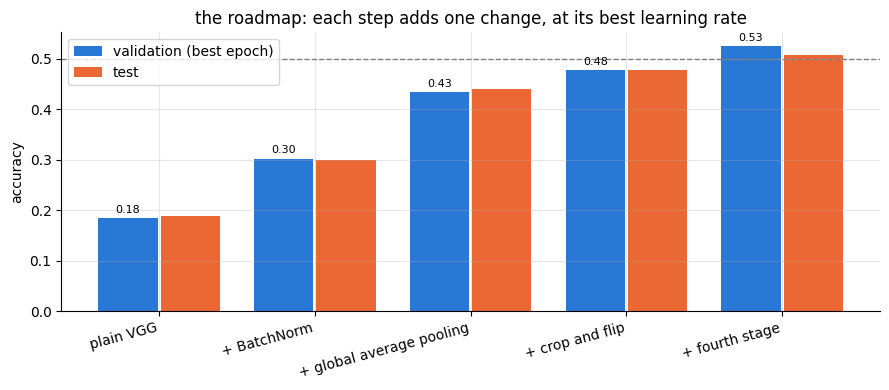

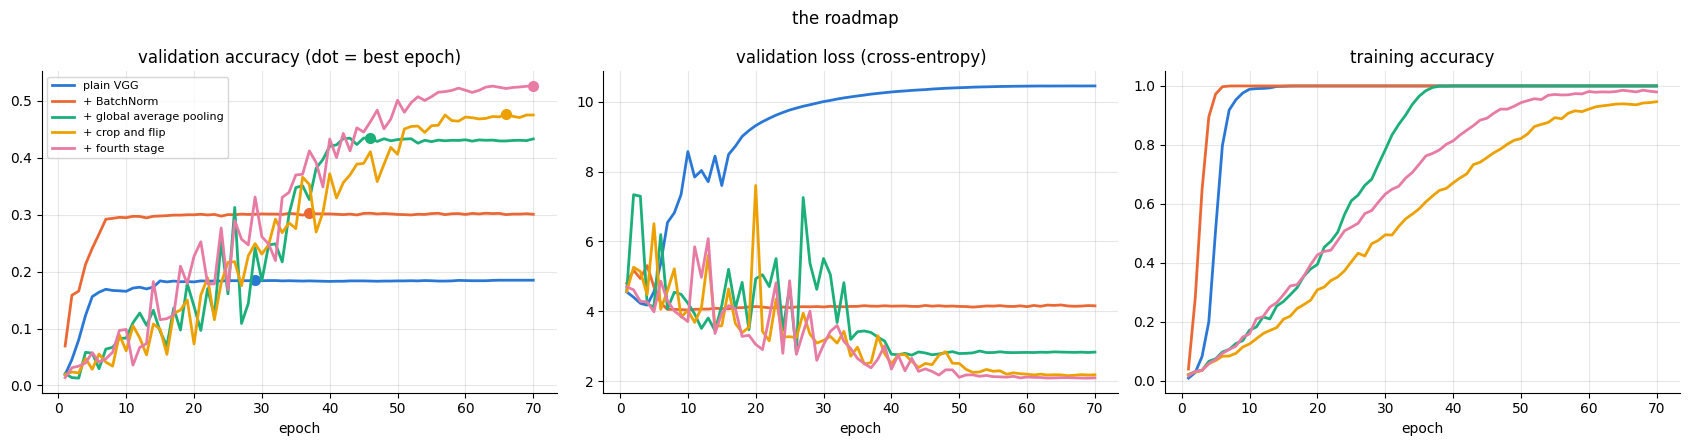

In [ ]:
ladder = load_group("ladder")
steps = {n: best_of(ladder, n) for n, _ in LADDER}
steps = {n: r for n, r in steps.items() if r}
if steps:
    display(summary(steps))

    names = list(steps)
    xs = np.arange(len(names))
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar(xs - 0.2, [steps[n]["best_val_acc"] for n in names], 0.38, label="validation (best epoch)", color=COLORS[0])
    ax.bar(xs + 0.2, [steps[n]["test_acc"] for n in names], 0.38, label="test", color=COLORS[1])
    for x_, n in zip(xs, names):
        ax.text(x_ - 0.2, steps[n]["best_val_acc"] + 0.01, f"{steps[n]['best_val_acc']:.2f}", ha="center", fontsize=8)
    ax.set_xticks(xs, [label(n) for n in names], rotation=15, ha="right"); ax.set_ylabel("accuracy"); ax.axhline(0.5, ls="--", c="gray", lw=1)
    ax.legend(); ax.set_title("the roadmap: each step adds one change, at its best learning rate")
    plt.tight_layout(); plt.show()

    plot_curves(steps, "the roadmap")

**Every step improves the network**, from **18.5%** (plain VGG) to **52.6%** (fourth stage) validation accuracy: BatchNorm adds 11.7
points, global average pooling 13.3, crop and flip 4.2 and the fourth stage 4.9.

The curves show the mechanism. The first three networks reach **100% training accuracy**: they memorize the training
set. The plain VGG does it within about 15 epochs, after which its validation loss *rises* while its training loss goes to zero —
the network becomes confidently wrong on unseen images. BatchNorm and global average pooling make the memorizing
network generalize better, but do not stop memorization. Augmentation does: once crop and flip are added, the training accuracy stays
below 100% and the gap between training and validation accuracy shrinks.

### Sensitivity to the learning rate

Best validation accuracy of every step at each learning rate.

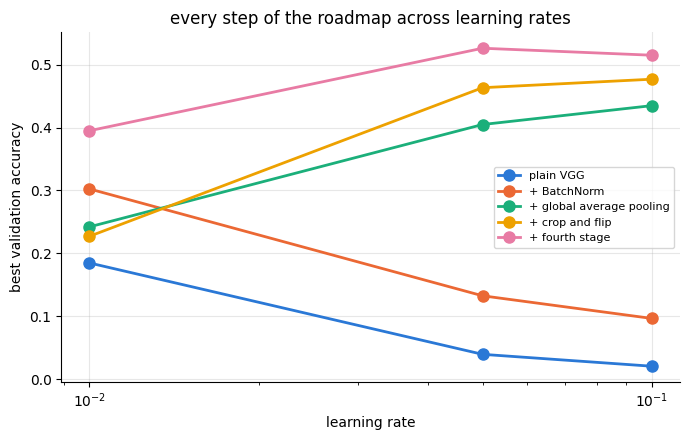

In [ ]:
if ladder:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for i, (name, _) in enumerate(LADDER):
        swept = sweep_runs(ladder, name)
        if swept:
            lrs = sorted(swept)
            ax.plot(lrs, [swept[lr]["best_val_acc"] for lr in lrs], "o-", color=COLORS[i], label=label(name), markersize=8)
    ax.set_xscale("log"); ax.set_xlabel("learning rate"); ax.set_ylabel("best validation accuracy")
    ax.set_title("every step of the roadmap across learning rates"); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

The plain VGG, without BatchNorm, diverges at learning rate 0.1 and reaches only 4% at 0.05; with BatchNorm every
learning rate trains, and the best one gives 11.7 more points — the tolerance to the learning rate promised by lecture 4
(*Batch norm: pros and cons*). After global average pooling the best learning rate moves from 0.01 to 0.05–0.1, and
0.01 becomes clearly worse. A single learning rate for every step would have penalized some of them: this is why
every configuration is compared at its own best.

With augmentation and a fourth stage the network is regularized and still improving: the next question is whether it
benefits from more depth.

## 2. Depth and residual connections

We replicate at small scale the central experiment of the ResNet paper (lecture 5, *Residual Networks*; He et al., 2016):
**identical plain and residual networks at increasing depth**. All six networks are the last network of the roadmap
with a different number of blocks per stage, with and without skip connections:

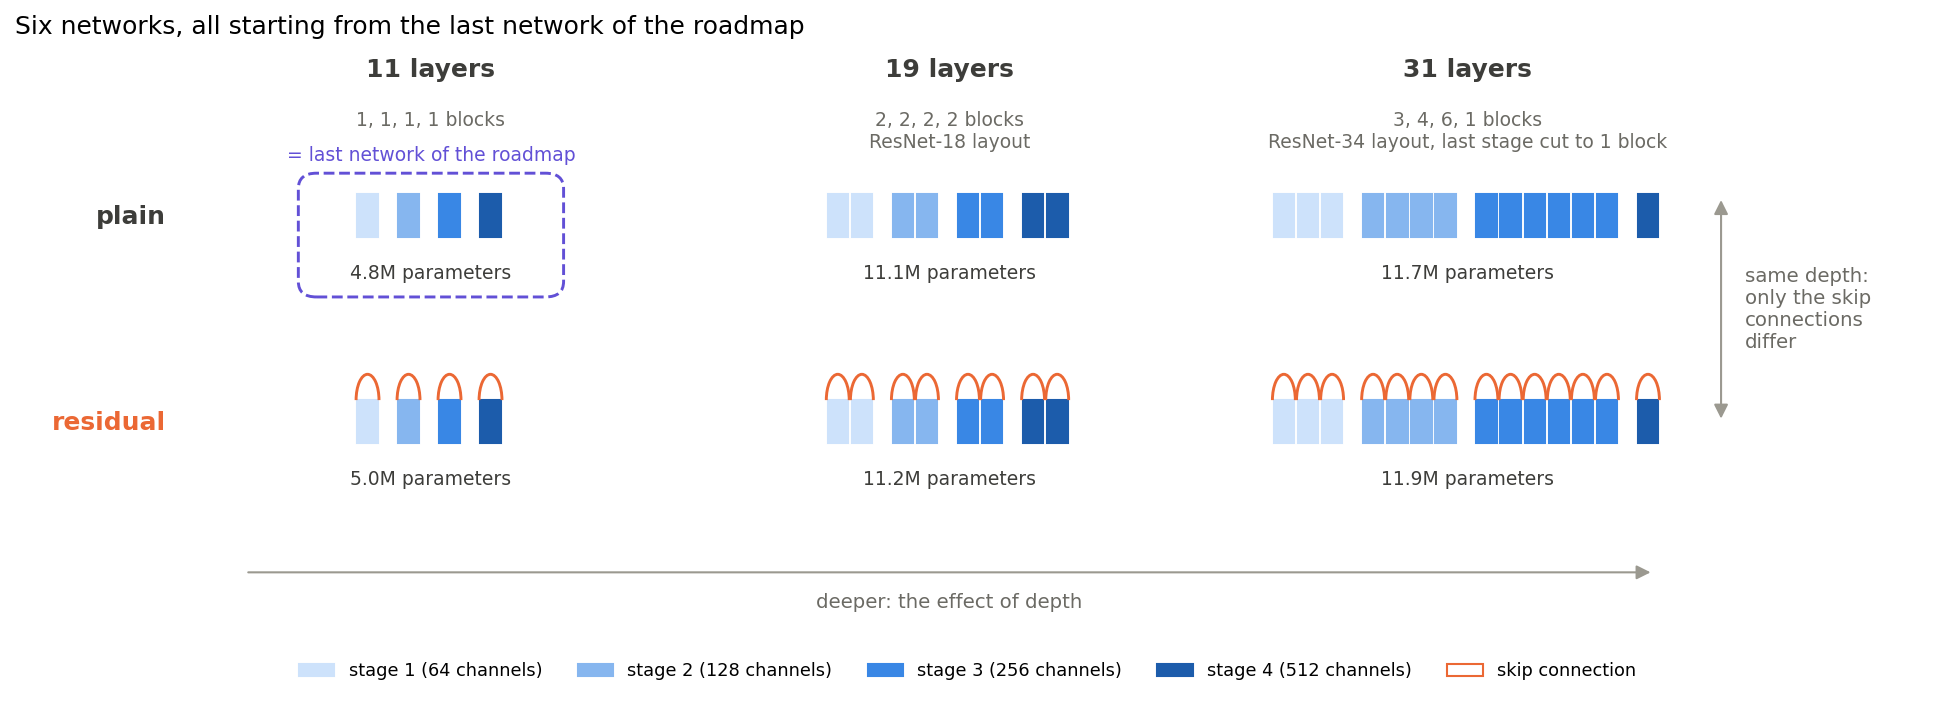


- **one block per stage**: 11 convolutional layers, 4.8M parameters — the last network of the roadmap itself;
- **two blocks per stage**: 19 layers, 11.1M — the stage layout of ResNet-18 (lecture 5, *Common variants on ImageNet*),
  where He et al. find plain and residual networks on par;
- **3, 4, 6 and 1 blocks**: 31 layers, 11.8M — the layout of ResNet-34 with one block in the last stage, where He et
  al. find the plain network *worse* than its shallower version. A 512-channel block alone costs 4.7M parameters, so
  the extra depth goes into the first three stages.

Within a depth, the two networks differ only by the skip connections. lecture 5 notes that deeper plain networks show
**higher training error**, so the problem is optimization, not overfitting: this is the signature to look for in the
training accuracy. Each network is trained at three learning rates, then with two more seeds at its best one, since
run-to-run variation (1–2 points) is comparable to the differences between networks.

In [ ]:
# [run]
for name, over in GRID:
    run_sweep(name, "depth_residual", **over)
report_runs()

==> plain, 11 layers: best learning rate 0.05 | validation 0.526 | test 0.507

==> residual, 11 layers: best learning rate 0.1 | validation 0.470 | test 0.465

==> plain, 19 layers: best learning rate 0.05 | validation 0.557 | test 0.545

==> residual, 19 layers: best learning rate 0.05 | validation 0.534 | test 0.522

==> plain, 31 layers: best learning rate 0.01 | validation 0.470 | test 0.483

==> residual, 31 layers: best learning rate 0.05 | validation 0.549 | test 0.552

runs loaded from the stored results: 18 | trained: 0


Two more seeds for every network, at its best learning rate.

In [ ]:
# [run]
for name, over in GRID:
    run_seeds(name, "depth_residual", note="seeds", **over)
report_runs()

runs loaded from the stored results: 12 | trained: 0


### Results

The six networks with their validation accuracy (mean ± standard deviation over three seeds) and training accuracy;
then the same numbers against depth — left validation, right training accuracy — and the training curves of the
seed-42 runs.

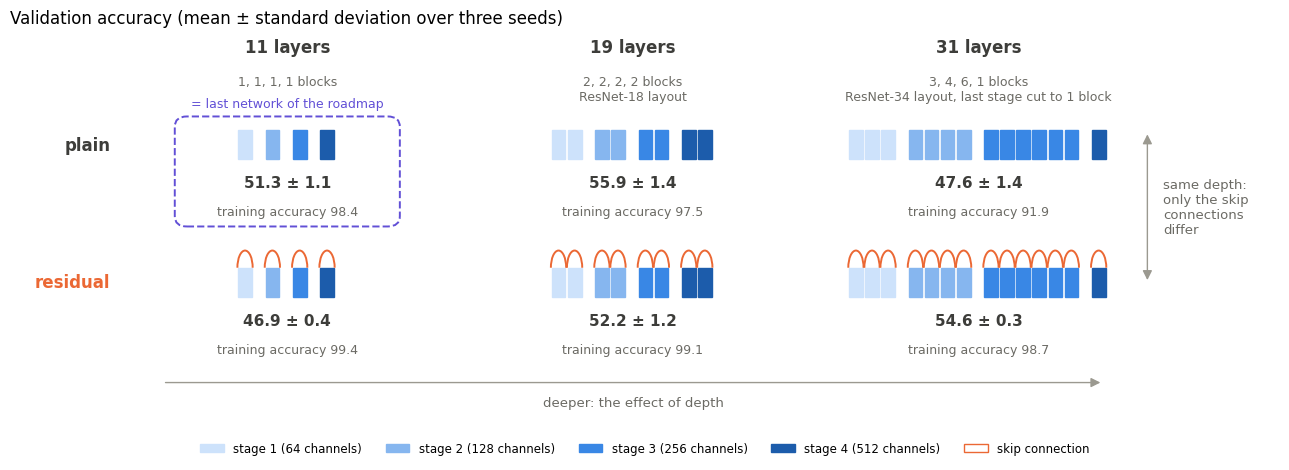

In [ ]:
from matplotlib.patches import Arc, FancyArrowPatch, FancyBboxPatch, Patch, Rectangle

STAGE_COLORS = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab"]       # stages 1-4: 64, 128, 256, 512 channels
SKIP_COLOR = COLORS[1]
DEPTH_COLUMNS = [("1111", "11 layers", "1, 1, 1, 1 blocks", ""),
                 ("2222", "19 layers", "2, 2, 2, 2 blocks", "ResNet-18 layout"),
                 ("3461", "31 layers", "3, 4, 6, 1 blocks", "ResNet-34 layout, last stage cut to 1 block")]


def draw_depth_grid(values=None, title=""):
    # The six networks of the experiment: plain / residual x three depths. Each block is a small box coloured by
    # stage; residual networks have an arc (the skip connection) over every block. values: {network: [text lines]}
    grid = dict(GRID)
    fig, ax = plt.subplots(figsize=(13, 4.8))
    col_x, cell_w, row_y = [0.0, 4.3, 8.6], 3.7, {"plain": 2.0, "res": 0.0}
    bw, bh, gap = 0.2, 0.42, 0.14
    for (key, depth, blocks, ref), x0 in zip(DEPTH_COLUMNS, col_x):
        ax.text(x0 + cell_w / 2, 4.45, depth, ha="center", fontsize=12, fontweight="bold", color="#3d3d3a")
        ax.text(x0 + cell_w / 2, 4.12, blocks + (f"\n{ref}" if ref else ""), ha="center", va="top", fontsize=9,
                color="#6b6a64")
        for kind, y0 in row_y.items():
            name = f"{kind}_{key}"
            n_blocks = grid[name]["blocks"]
            length = sum(n_blocks) * bw + (len(n_blocks) - 1) * gap
            x = x0 + (cell_w - length) / 2
            for stage, n in enumerate(n_blocks):
                for b in range(n):
                    ax.add_patch(Rectangle((x, y0 + 0.9), bw * 0.85, bh, color=STAGE_COLORS[stage]))
                    if kind == "res":
                        ax.add_patch(Arc((x + bw * 0.42, y0 + 0.9 + bh), bw * 0.95, 0.5, theta1=0, theta2=180,
                                         color=SKIP_COLOR, lw=1.4))
                    x += bw
                x += gap
            lines = values.get(name, []) if values is not None else \
                [f"{count_params(AircraftNet({**BASE, **grid[name]}, N_CLASSES)) / 1e6:.1f}M parameters"]
            for k, line in enumerate(lines):
                ax.text(x0 + cell_w / 2, y0 + 0.55 - 0.42 * k, line, ha="center", va="center",
                        fontsize=11 if k == 0 and values is not None else 9,
                        fontweight="bold" if k == 0 and values is not None else "normal",
                        color="#3d3d3a" if k == 0 else "#6b6a64")
    for kind, y0 in row_y.items():
        ax.text(-0.35, y0 + 1.1, "plain" if kind == "plain" else "residual", ha="right", va="center", fontsize=12,
                fontweight="bold", color=SKIP_COLOR if kind == "res" else "#3d3d3a")
    # the plain 11-layer network is the last network of the roadmap: framed in the colour of that step
    bottom = row_y["plain"] + (-0.08 if values is not None else 0.32)
    ax.add_patch(FancyBboxPatch((0.45, bottom), cell_w - 0.9, row_y["plain"] + 1.52 - bottom,
                                boxstyle="round,pad=0,rounding_size=0.15", facecolor="none",
                                edgecolor=COLORS[6], lw=1.4, ls="--"))
    ax.text(cell_w / 2, row_y["plain"] + 1.6, "= last network of the roadmap", ha="center", va="bottom",
            fontsize=9, color=COLORS[6])
    # how to read the grid
    ax.add_patch(FancyArrowPatch((0.3, -0.35), (12.0, -0.35), arrowstyle="-|>", mutation_scale=14, color="#9b9990"))
    ax.text(6.15, -0.55, "deeper: the effect of depth", ha="center", va="top", fontsize=9.5, color="#6b6a64")
    ax.add_patch(FancyArrowPatch((12.55, 3.3), (12.55, 1.1), arrowstyle="<|-|>", mutation_scale=14, color="#9b9990"))
    ax.text(12.75, 2.2, "same depth:\nonly the skip\nconnections\ndiffer", ha="left", va="center", fontsize=9.5,
            color="#6b6a64")
    handles = [Patch(color=c, label=f"stage {i + 1} ({ch} channels)")
               for i, (c, ch) in enumerate(zip(STAGE_COLORS, (64, 128, 256, 512)))]
    handles.append(Patch(facecolor="none", edgecolor=SKIP_COLOR, label="skip connection"))
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=5, fontsize=8.5, frameon=False)
    ax.set_xlim(-1.6, 14.2); ax.set_ylim(-0.95, 4.75); ax.axis("off")
    if title:
        ax.set_title(title, fontsize=12, loc="left")
    plt.tight_layout(); plt.show()



grid_runs = {n: seed_runs(n, "depth_residual") for n, _ in GRID}
grid_runs = {n: r for n, r in grid_runs.items() if r}
if len(grid_runs) == len(GRID):
    draw_depth_grid({n: [f"{100 * seed_mean(r):.1f} ± {100 * seed_std(r):.1f}",
                         f"training accuracy {100 * seed_mean(r, 'final_train_acc'):.1f}"]
                     for n, r in grid_runs.items()},
                    title="Validation accuracy (mean ± standard deviation over three seeds)")

,learning rate,seeds,parameters (M),validation (mean),validation (std),test (mean),test (std),final training (mean)
network,,,,,,,,
"plain, 11 layers",0.05,3,4.80,0.513,0.011,0.501,0.014,0.984
"residual, 11 layers",0.1,3,4.98,0.469,0.004,0.460,0.004,0.994
"plain, 19 layers",0.05,3,11.07,0.559,0.014,0.551,0.012,0.975
"residual, 19 layers",0.05,3,11.25,0.522,0.012,0.519,0.003,0.991
"plain, 31 layers",0.01,3,11.74,0.476,0.014,0.482,0.013,0.919
"residual, 31 layers",0.05,3,11.91,0.546,0.003,0.545,0.008,0.987


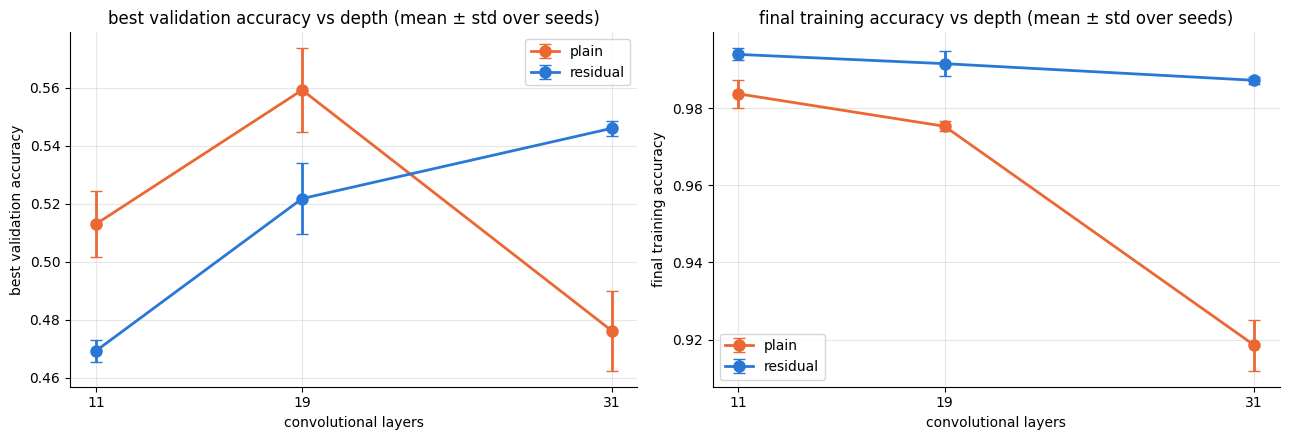

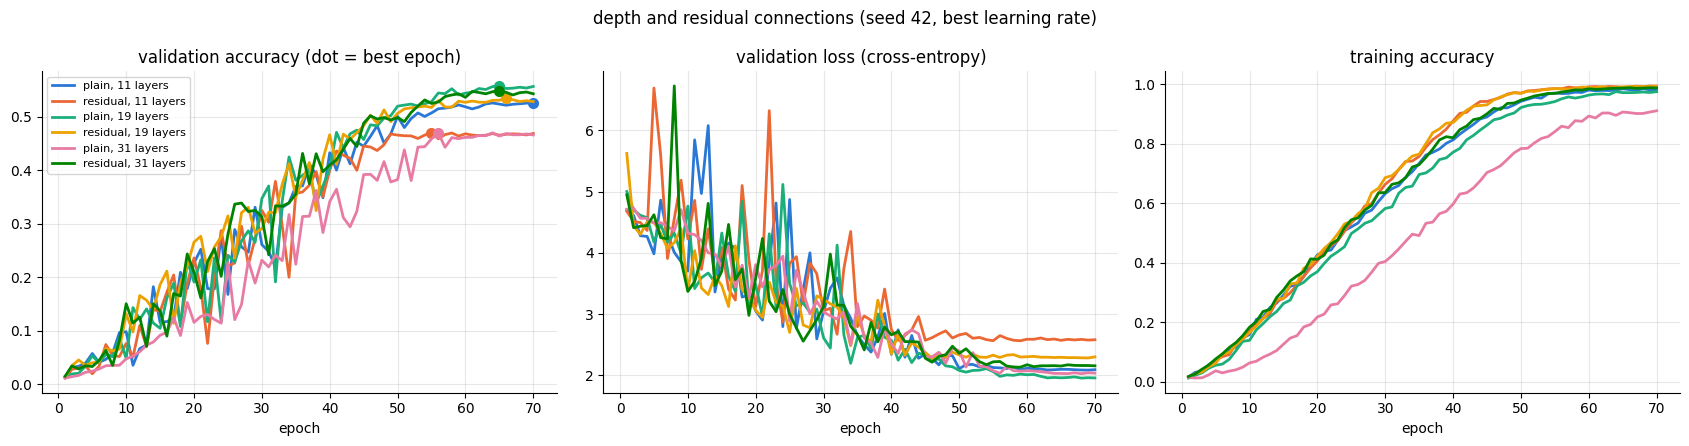

In [ ]:
grid_runs = {n: seed_runs(n, "depth_residual") for n, _ in GRID}
grid_runs = {n: r for n, r in grid_runs.items() if r}
if grid_runs:
    display(seed_summary(grid_runs))

    convs = {n: 3 + 2 * sum(dict(GRID)[n]["blocks"]) for n in grid_runs}
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for kind, kind_label, c in (("plain", "plain", COLORS[1]), ("res", "residual", COLORS[0])):
        names = [n for n in grid_runs if n.startswith(kind + "_")]
        if not names:
            continue
        for ax, key in zip(axes, ("best_val_acc", "final_train_acc")):
            ax.errorbar([convs[n] for n in names], [seed_mean(grid_runs[n], key) for n in names],
                        yerr=[np.nan_to_num(seed_std(grid_runs[n], key)) for n in names],
                        fmt="o-", color=c, capsize=4, markersize=8, label=kind_label)
    for ax, t in zip(axes, ("best validation accuracy", "final training accuracy")):
        ax.set_xlabel("convolutional layers"); ax.set_ylabel(t); ax.set_xticks(sorted(set(convs.values())))
        ax.set_title(f"{t} vs depth (mean ± std over seeds)"); ax.legend()
    plt.tight_layout(); plt.show()

    plot_curves({n: r[0] for n, r in grid_runs.items()}, "depth and residual connections (seed 42, best learning rate)")

**Starting point.** The plain 11-layer network is the last network of the roadmap (framed in the figure), trained
again with the same configuration: its seed-42 runs reproduce the numbers of the roadmap exactly, since training is
deterministic for a fixed seed. Its two extra seeds only add the standard deviation.

**Degradation.** From 19 to 31 layers the plain network loses 8.3 points (55.9% → 47.6%), and its *training* accuracy
drops too (97.5% → 91.9%): the deeper plain network is harder to optimize — the degradation problem described in lecture 5.
The residual network improves at every depth (46.9% → 52.2% → 54.6%) and keeps fitting its training set: skip
connections make depth usable.

**Shallow networks.** At 11 and 19 layers the residual networks are about 4 points *worse* than the plain ones, well
beyond the seed noise, while reaching a higher training accuracy (99% against 97–98%). Without any regularization,
the ease of fitting that skip connections provide turns into more overfitting on 33 images per class. If this is the
cause, regularization should help the residual networks more than the plain ones — the question of the next section.

## 3. The training recipe

We regularize the three best networks of the previous experiment and tune their training recipe, combining standard
techniques from lecture 6 (*Regularization*):

- **Weight decay** (lecture 6, *l2 regularization or weight decay*) penalizes large weights.
- **Label smoothing** (lecture 6, *Label smoothing*; Szegedy et al., 2016) replaces the one-hot target with 1−ε on the true
  class and ε spread over the others, so the network is not pushed towards infinite confidence.
- **Dropout** before the classifier (lecture 6, *Dropout*), between global pooling and the last linear layer. lecture 6 notes it is
  not used in ResNets, for its unclear interaction with BatchNorm (*Dropout: where*): zero is a real candidate.
- **Random erasing** (lecture 6, *Cutout (Random Erasing)*; Zhong et al., 2020) hides a random rectangle of the image.
- **Minimum crop area** of the random resized crop: smaller crops show parts of the aircraft at a larger scale
  (lecture 6, *multi-scale training*).
- **One-cycle schedule** (lecture 6, *Learning rate schedule: One cycle*; Smith & Topin, 2019): the learning rate rises over
  the first 30% of training, then decays to almost zero.

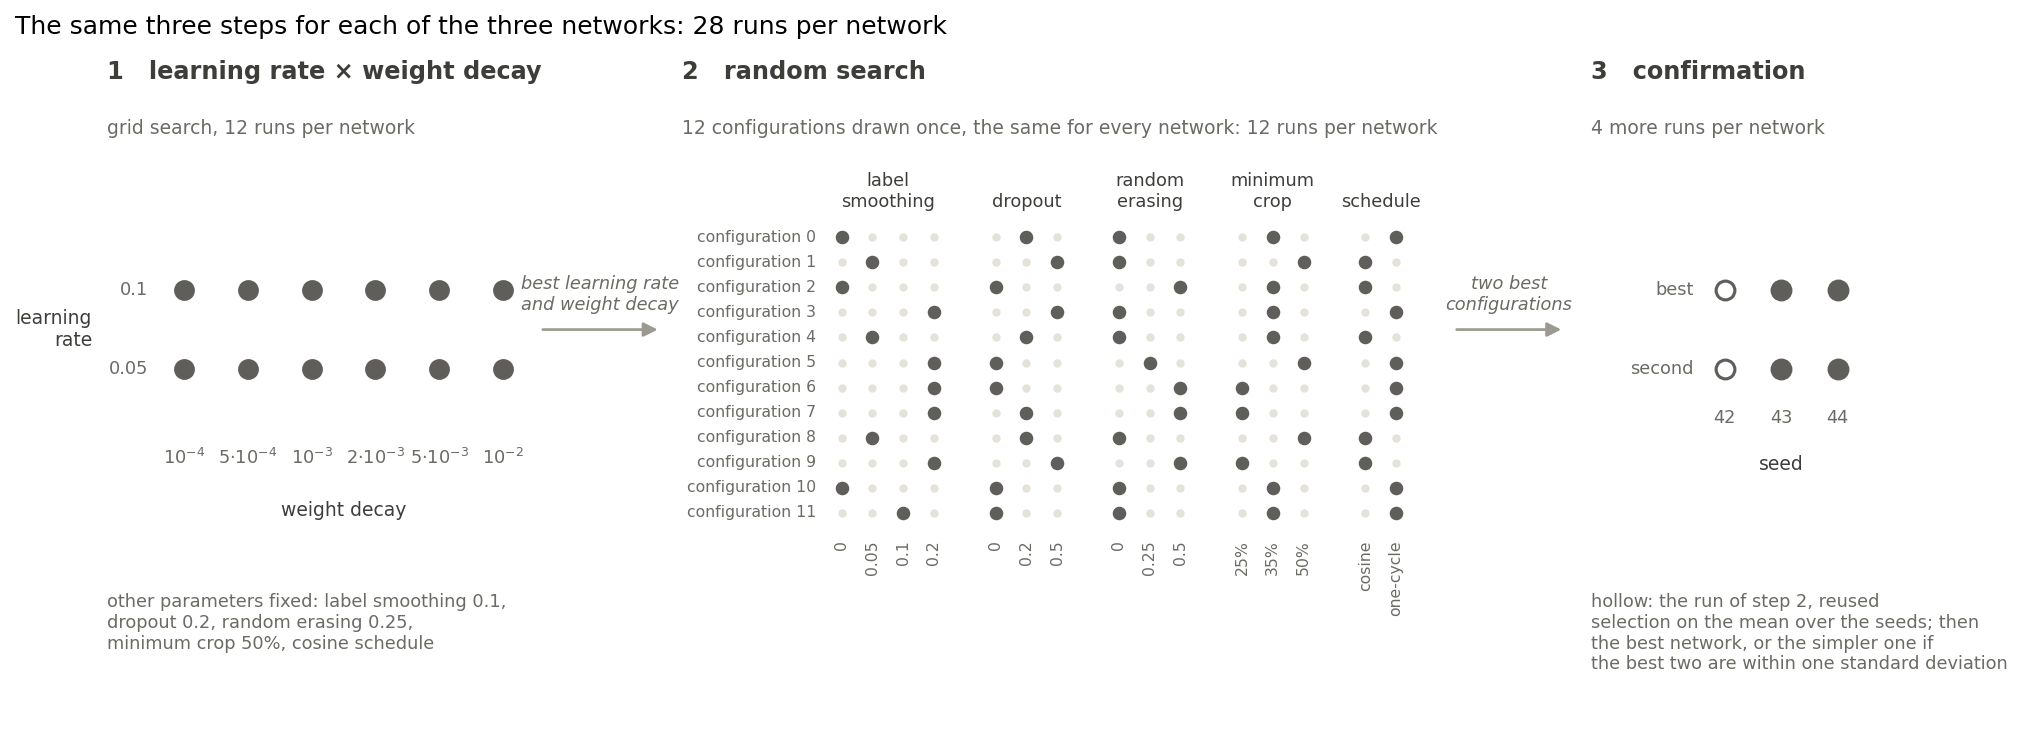

We tune the recipe in three steps, following lecture 6 (*Random hyper-parameters search*):

1. **Grid search on learning rate x weight decay**, the two most influential parameters, log-spaced, with the other
   parameters fixed (label smoothing 0.1, dropout 0.2, random erasing 0.25, minimum crop 50%, cosine schedule).
2. **Random search** on the other five parameters (Bergstra & Bengio, 2012), at the best learning rate and weight
   decay of each network: a full grid would require 216 runs per network, so we draw 12 configurations once and
   train the same 12 on every network.
3. **Confirmation with seeds**: the best of many single runs is partly the luckiest, so the two best configurations of
   each network are retrained with two more seeds and compared on the mean.

**Networks.** The 19-layer plain network and the 31-layer residual network are the two best; the 19-layer residual
network is third but overfits the most, so it is the network regularization can help most. The 31-layer plain network
is excluded because it does not fit its training set — an optimization problem regularization cannot fix — and the
11-layer networks trail the best by 5–9 points. All three
networks receive the same tuning budget, so that the comparison remains fair.

**Selection rule.** The best configuration of each network by mean validation accuracy; then the best network, or
the simpler one if the best two are within one standard deviation.

Mixup, CutMix and the exponential moving average of the weights (lecture 6) are left out: they mainly pay off with schedules
much longer than ours.

### Step 1 — learning rate and weight decay

Best validation accuracy of every point of the grid (seed 42), one panel per network; the ring marks the best point.

In [ ]:
# [run]
names = finalists(TUNE_N)
if names is None:
    print("train the whole grid with all its seeds first")
else:
    print("networks:", ", ".join(label(n) for n in names))
    # 1. grid search: learning rate x weight decay, the other parameters as in RECIPE
    for name in names:
        for lr in TUNE_LRS:
            for wd in TUNE_WDS:
                run_experiment(f"{name}_lr{lr:g}_wd{wd:g}", "tune_grid", note="tuning: lr x wd",
                               **{**dict(GRID)[name], **RECIPE, "lr": lr, "weight_decay": wd})
        lr, wd = best_grid_point(name)
        print(f"==> {label(name)}: best learning rate {lr:g}, weight decay {wd:g}\n")
report_runs()

networks: plain, 19 layers, residual, 31 layers, residual, 19 layers
==> plain, 19 layers: best learning rate 0.05, weight decay 0.002

==> residual, 31 layers: best learning rate 0.05, weight decay 0.005

==> residual, 19 layers: best learning rate 0.05, weight decay 0.005

runs loaded from the stored results: 36 | trained: 0


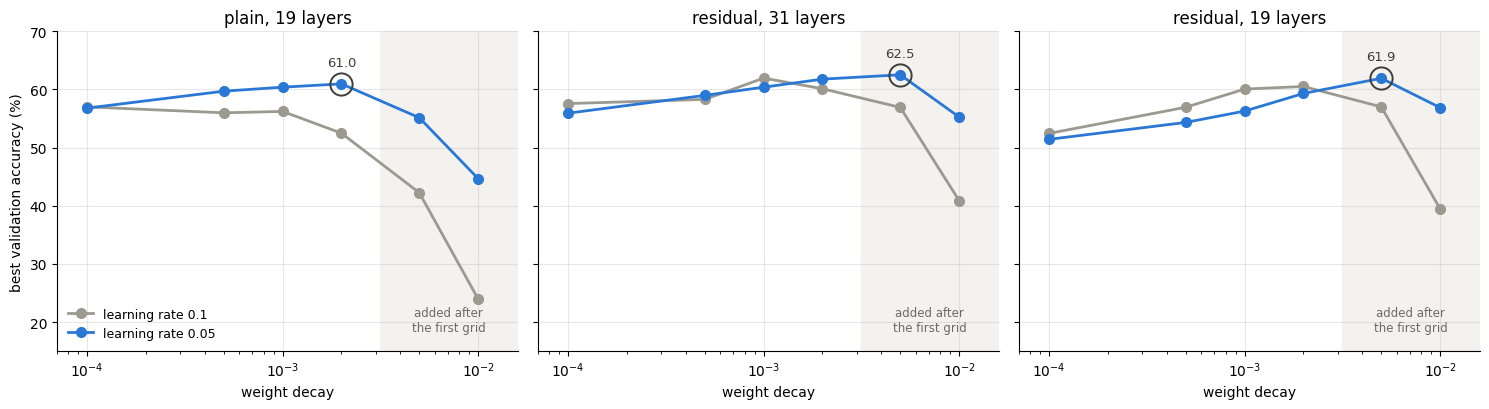

In [ ]:
FIRST_GRID_MAX_WD = 2e-3      # the first grid stopped here: the larger weight decays were added afterwards

names = finalists(TUNE_N) or []
grid_runs_t = load_group("tune_grid")
if names and grid_runs_t:
    fig, axes = plt.subplots(1, len(names), figsize=(15, 4.2), sharey=True)
    for ax, name in zip(axes, names):
        ax.axvspan(np.sqrt(FIRST_GRID_MAX_WD * 5e-3), 1.6e-2, color="#f3f2ee", zorder=0)
        ax.text(np.sqrt(5e-3 * 1e-2), 18.5, "added after\nthe first grid", ha="center", fontsize=8.5, color="#6b6a64")
        points = []
        for lr, c in zip(TUNE_LRS, ("#9b9990", COLORS[0])):
            acc = [100 * grid_runs_t.get(f"{name}_lr{lr:g}_wd{wd:g}", {}).get("best_val_acc", np.nan) for wd in TUNE_WDS]
            ax.plot(TUNE_WDS, acc, "o-", color=c, lw=2, markersize=7, label=f"learning rate {lr:g}")
            points += zip(TUNE_WDS, acc)
        wd, acc = max(points, key=lambda p: np.nan_to_num(p[1]))
        ax.plot(wd, acc, "o", markersize=16, markerfacecolor="none", markeredgecolor="#3d3d3a", markeredgewidth=1.4)
        ax.annotate(f"{acc:.1f}", (wd, acc), xytext=(0, 13), textcoords="offset points", ha="center", fontsize=9.5,
                    color="#3d3d3a")
        ax.set_xscale("log"); ax.set_xlim(7e-5, 1.6e-2); ax.set_ylim(15, 70)
        ax.set_title(label(name)); ax.set_xlabel("weight decay")
    axes[0].set_ylabel("best validation accuracy (%)"); axes[0].legend(loc="lower left", fontsize=9, frameon=False)
    plt.tight_layout(); plt.show()


Accuracy increases with weight decay up to **2e-3 for the plain network and 5e-3 for both residual networks**, then drops
sharply at 1e-2. The grid initially stopped at 2e-3, which was the best value for two networks; since an optimum at
the edge of a grid may lie beyond it, we extended the grid until accuracy decreased (shaded area), and the optimum now lies inside
it. The residual networks, which fit their training set more easily, need the stronger regularization. With strong
weight decay, a learning rate of 0.05 is better than 0.1.

### Step 2 — random search

Every configuration on every network (seed 42), sorted by the mean over the networks; in the plot every configuration is a
line through its parameter values, ending at its mean accuracy over the three networks (blue: the two best).

In [ ]:
# [run]
# 2. random search on the other parameters, at the best lr and weight decay of each network
configs = random_configs()
for name in finalists(TUNE_N):
    lr, wd = best_grid_point(name)
    for i, c in enumerate(configs):
        run_experiment(f"{name}_cfg{i:02d}", "tune_random", note="tuning: random search",
                       **{**dict(GRID)[name], **RECIPE, "lr": lr, "weight_decay": wd, **c})
report_runs()

configuration 1: {'label_smoothing': 0.0, 'dropout': 0.2, 'random_erasing': 0.0, 'crop_scale': (0.35, 1.0), 'schedule': 'onecycle'}
configuration 2: {'label_smoothing': 0.05, 'dropout': 0.5, 'random_erasing': 0.0, 'crop_scale': (0.5, 1.0)}
configuration 3: {'label_smoothing': 0.0, 'dropout': 0.0, 'random_erasing': 0.5, 'crop_scale': (0.35, 1.0)}
configuration 4: {'label_smoothing': 0.2, 'dropout': 0.5, 'random_erasing': 0.0, 'crop_scale': (0.35, 1.0), 'schedule': 'onecycle'}
configuration 5: {'label_smoothing': 0.05, 'dropout': 0.2, 'random_erasing': 0.0, 'crop_scale': (0.35, 1.0)}
configuration 6: {'label_smoothing': 0.2, 'dropout': 0.0, 'random_erasing': 0.25, 'crop_scale': (0.5, 1.0), 'schedule': 'onecycle'}
configuration 7: {'label_smoothing': 0.2, 'dropout': 0.0, 'random_erasing': 0.5, 'crop_scale': (0.25, 1.0), 'schedule': 'onecycle'}
configuration 8: {'label_smoothing': 0.2, 'dropout': 0.2, 'random_erasing': 0.5, 'crop_scale': (0.25, 1.0), 'schedule': 'onecycle'}
configuration 9

,label smoothing,dropout,random erasing,minimum crop,schedule,"plain, 19 layers","residual, 31 layers","residual, 19 layers",mean
configuration,,,,,,,,,
configuration 6,0.200000,0.000000,0.250000,0.500000,onecycle,0.618,0.644,0.647,0.636
configuration 12,0.100000,0.000000,0.000000,0.350000,onecycle,0.615,0.651,0.622,0.629
configuration 9,0.050000,0.200000,0.000000,0.500000,cosine,0.593,0.630,0.627,0.617
configuration 11,0.000000,0.000000,0.000000,0.350000,onecycle,0.595,0.633,0.616,0.615
configuration 1,0.000000,0.200000,0.000000,0.350000,onecycle,0.603,0.629,0.611,0.614
configuration 4,0.200000,0.500000,0.000000,0.350000,onecycle,0.598,0.612,0.623,0.611
configuration 2,0.050000,0.500000,0.000000,0.500000,cosine,0.586,0.605,0.611,0.600
configuration 5,0.050000,0.200000,0.000000,0.350000,cosine,0.559,0.624,0.606,0.596
configuration 8,0.200000,0.200000,0.500000,0.250000,onecycle,0.559,0.546,0.566,0.557


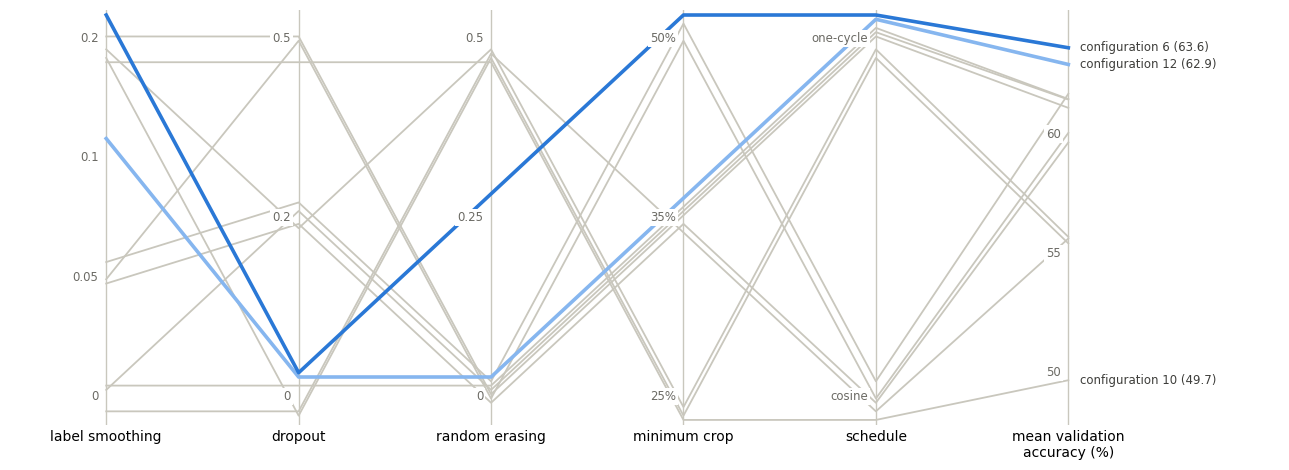

In [ ]:
random_runs = load_group("tune_random")
configs = random_configs()
if names and random_runs:
    rows = []
    for i, c in enumerate(configs):
        row = {"configuration": label(f"cfg{i:02d}"), "label smoothing": c["label_smoothing"],
               "dropout": c["dropout"], "random erasing": c["random_erasing"], "minimum crop": c["crop_scale"][0],
               "schedule": c.get("schedule", "cosine")}
        for name in names:
            r = random_runs.get(f"{name}_cfg{i:02d}")
            row[label(name)] = r["best_val_acc"] if r else np.nan
        rows.append(row)
    table = pd.DataFrame(rows).set_index("configuration")
    nets = [label(n) for n in names]
    table["mean"] = table[nets].mean(axis=1)
    display(table.sort_values("mean", ascending=False).style.format({n: "{:.3f}" for n in nets + ["mean"]}))

    # parallel coordinates: one vertical axis per parameter, the last one for the mean accuracy
    params = ["label smoothing", "dropout", "random erasing", "minimum crop", "schedule"]
    levels = {p: sorted(table[p].unique(), key=str) for p in params}
    lo, hi = np.floor(table["mean"].min() * 100) / 100, np.ceil(table["mean"].max() * 100) / 100
    order = table.sort_values("mean")                       # the two most accurate, in blue, are drawn last
    tag = dict(fc="white", ec="none", pad=1.5)
    fig, ax = plt.subplots(figsize=(13, 4.8))
    for rank, (cfg, row) in enumerate(order.iterrows()):
        shift = (rank - (len(order) - 1) / 2) * 0.012       # separates the lines that share a value
        ys = [levels[p].index(row[p]) / (len(levels[p]) - 1) + shift for p in params]
        ys.append((row["mean"] - lo) / (hi - lo))
        top = rank >= len(order) - 2
        ax.plot(range(len(ys)), ys, color=(COLORS[0] if rank == len(order) - 1 else "#86b6ef") if top else "#c9c7bd",
                lw=2.6 if top else 1.3, zorder=3 + rank)
        if top or rank == 0:
            ax.text(len(params) + 0.06, ys[-1], f"{cfg} ({100 * row['mean']:.1f})", va="center", fontsize=8.5,
                    color="#3d3d3a")
    for k, p in enumerate(params):
        ax.axvline(k, color="#c9c7bd", lw=1, zorder=1)
        for j, v in enumerate(levels[p]):
            text = ("one-cycle" if v == "onecycle" else f"{v:.0%}" if p == "minimum crop" else
                    f"{v:g}" if isinstance(v, float) else str(v))
            ax.text(k - 0.04, j / (len(levels[p]) - 1), text, ha="right", va="center", fontsize=8.5, color="#6b6a64",
                    bbox=tag, zorder=20)
    ax.axvline(len(params), color="#c9c7bd", lw=1, zorder=1)
    for v in np.arange(np.ceil(lo * 20) / 20, hi, 0.05):
        ax.text(len(params) - 0.04, (v - lo) / (hi - lo), f"{100 * v:.0f}", ha="right", va="center", fontsize=8.5,
                color="#6b6a64", bbox=tag, zorder=20)
    ax.set_xticks(range(len(params) + 1), params + ["mean validation\naccuracy (%)"])
    ax.set_yticks([]); ax.set_xlim(-0.5, len(params) + 1.1); ax.set_ylim(-0.08, 1.08)
    ax.spines[["left", "right", "top", "bottom"]].set_visible(False); ax.grid(False)
    ax.tick_params(axis="x", length=0)
    plt.tight_layout(); plt.show()


The ranking is consistent across networks: the same configuration (configuration 5, the dark blue line) — **label smoothing 0.2, no dropout,
random erasing 0.25, minimum crop 50%, one-cycle schedule** — is the best or second best for all three. The one-cycle schedule
appears in the best configurations, no dropout in the two best — consistent with lecture 6's remark on dropout and
BatchNorm — and random erasing at 0.5 in all of the worst ones. Since each run changes several parameters at once,
these are tendencies; the ablation study measures each component in isolation.

### Step 3 — confirmation with seeds

The two best configurations of each network, mean ± standard deviation over three seeds.

In [ ]:
# [run]
# 3. confirmation: the TOP_K best configurations of each network, with the other seeds
for name in finalists(TUNE_N):
    for run in top_configs(name):
        for seed in SEEDS[1:]:
            run_experiment(f"{run['name']}_s{seed}", "tune_seeds", note="tuning: seeds",
                           **{**run_overrides(run), "seed": seed})
report_runs()

runs loaded from the stored results: 12 | trained: 0


,learning rate,seeds,parameters (M),validation (mean),validation (std),test (mean),test (std),final training (mean)
network,,,,,,,,
"plain, 19 layers | configuration 6",0.05,3,11.07,0.630,0.011,0.631,0.008,0.892
"plain, 19 layers | configuration 12",0.05,3,11.07,0.608,0.006,0.599,0.010,0.928
"residual, 31 layers | configuration 12",0.05,3,11.91,0.638,0.012,0.633,0.011,0.949
"residual, 31 layers | configuration 6",0.05,3,11.91,0.642,0.003,0.647,0.005,0.905
"residual, 19 layers | configuration 6",0.05,3,11.25,0.641,0.007,0.640,0.003,0.931
"residual, 19 layers | configuration 9",0.05,3,11.25,0.627,0.001,0.623,0.010,0.978


residual, 31 layers  best: configuration 6 | validation 0.642 ± 0.003 | test 0.647 ± 0.005
residual, 19 layers  best: configuration 6 | validation 0.641 ± 0.007 | test 0.640 ± 0.003
plain, 19 layers     best: configuration 6 | validation 0.630 ± 0.011 | test 0.631 ± 0.008
-> a tie (0.001 <= 0.007): the simpler network, residual, 19 layers
final configuration: {'img_size': 224, 'augment': True, 'crop_scale': [0.5, 1.0], 'stem': [32, 32, 64], 'channels': [64, 128, 256, 512], 'blocks': [2, 2, 2, 2], 'batchnorm': True, 'gap': True, 'residual': True, 'dropout': 0.0, 'epochs': 70, 'batch_size': 64, 'lr': 0.05, 'momentum': 0.9, 'weight_decay': 0.005, 'label_smoothing': 0.2, 'random_erasing': 0.25, 'warmup_epochs': 3, 'schedule': 'onecycle'}


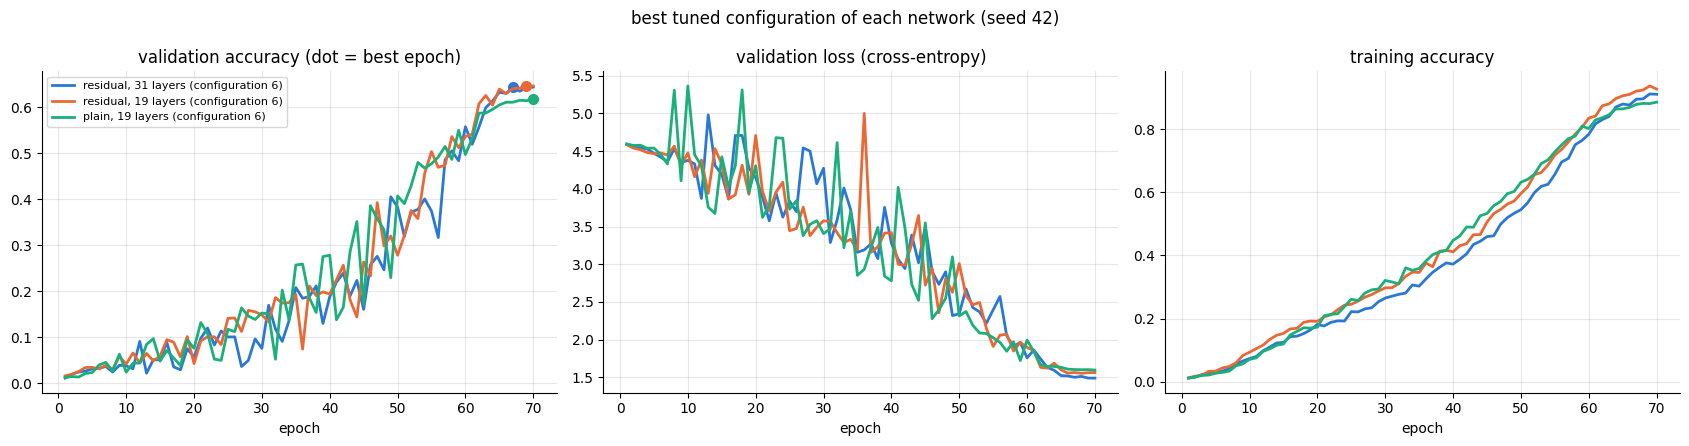

In [ ]:
if names:
    groups, best_per_net = {}, {}
    for name in names:
        for n, runs in confirmed(name).items():
            if len(runs) == len(SEEDS):
                groups[f"{label(name)} | {label(n.removeprefix(name + '_'))}"] = runs
        if best_tuned(name):
            best_per_net[name] = best_tuned(name)
    if groups:
        display(seed_summary(groups))
    if len(best_per_net) == len(names):
        ranked, selected = select({n: runs for n, (_, runs) in best_per_net.items()})
        print("configuration:", run_overrides(best_per_net[selected][1][0]))
        plot_curves({f"{label(n)} ({label(best_per_net[n][0].removeprefix(n + '_'))})": best_per_net[n][1][0]
                     for n in ranked}, "best tuned configuration of each network (seed 42)")

All three networks select that same configuration, which brings them to 63–64% validation accuracy, 7–12 points above their
unregularized versions. Tuning confirms the hypothesis of the depth experiment: without regularization
the 19-layer residual network was 3.7 points *worse* than the plain one; with the tuned recipe it is 1.1 points
*better*. The ease of fitting given by the skip connections turns into accuracy once overfitting is controlled.

At 70 epochs the two residual networks are within 0.1 points, so our rule would select the simpler one. However, all
three networks reach their best validation accuracy in the last epochs, with a training accuracy still around 90%:
they are still improving when training stops.

**Limitation.** The search is staged — architecture first, then recipe; learning rate and weight decay before the
other parameters — so it assumes the effects to be roughly independent. The flip in the ranking of the 19-layer plain and
residual networks shows that they are not entirely: this is why we tuned three networks rather than one, and why the ablation
measures every component on the final model.

## 4. Longer training and the final model

We train the three tuned networks again for **150 epochs**, each with its best configuration and no other change,
with three seeds each. The one-cycle schedule is defined in fractions of the training, so it stretches with the number
of epochs: in the middle of a longer run the learning rate is still high, and validation accuracy only rises during
the final decay. Since the recipe was tuned for 70 epochs, a longer training also gives more time to overfit: we check
that the gap between training and validation accuracy does not grow. The final model is selected with the same rule.

In [ ]:
# [run]
for name in finalists(TUNE_N):
    best = best_tuned(name)
    if best is None:
        print(f"{label(name)}: train the recipe search with all its seeds first")
        continue
    cfg_name, runs = best
    print(f"{label(name)}: {label(cfg_name.removeprefix(name + '_'))}, {LONG_EPOCHS} epochs")
    for seed in SEEDS:
        run_experiment(f"{name}_ep{LONG_EPOCHS}_s{seed}", "long", note=f"{cfg_name}, {LONG_EPOCHS} epochs",
                       **{**run_overrides(runs[0]), "epochs": LONG_EPOCHS, "seed": seed})
report_runs()

plain, 19 layers: configuration 6, 150 epochs
residual, 31 layers: configuration 6, 150 epochs
residual, 19 layers: configuration 6, 150 epochs
runs loaded from the stored results: 9 | trained: 0


### Results

Each tuned network at 70 and at 150 epochs (mean ± standard deviation over three seeds) and the selection rule at 150
epochs; the curves compare the two budgets (seed 42).

,learning rate,seeds,parameters (M),validation (mean),validation (std),test (mean),test (std),final training (mean)
network,,,,,,,,
"plain, 19 layers | 70 epochs",0.05,3,11.07,0.630,0.011,0.631,0.008,0.892
"plain, 19 layers | 150 epochs",0.05,3,11.07,0.724,0.005,0.720,0.006,0.978
"residual, 31 layers | 70 epochs",0.05,3,11.91,0.642,0.003,0.647,0.005,0.905
"residual, 31 layers | 150 epochs",0.05,3,11.91,0.740,0.007,0.742,0.002,0.982
"residual, 19 layers | 70 epochs",0.05,3,11.25,0.641,0.007,0.640,0.003,0.931
"residual, 19 layers | 150 epochs",0.05,3,11.25,0.708,0.004,0.712,0.006,0.985


residual, 31 layers  150 epochs: validation 0.740 ± 0.007 | test 0.742 ± 0.002 | train 0.982
plain, 19 layers     150 epochs: validation 0.724 ± 0.005 | test 0.720 ± 0.006 | train 0.978
residual, 19 layers  150 epochs: validation 0.708 ± 0.004 | test 0.712 ± 0.006 | train 0.985
-> residual, 31 layers: better by 0.017, more than one standard deviation (0.007)
final configuration: {'img_size': 224, 'augment': True, 'crop_scale': [0.5, 1.0], 'stem': [32, 32, 64], 'channels': [64, 128, 256, 512], 'blocks': [3, 4, 6, 1], 'batchnorm': True, 'gap': True, 'residual': True, 'dropout': 0.0, 'epochs': 150, 'batch_size': 64, 'lr': 0.05, 'momentum': 0.9, 'weight_decay': 0.005, 'label_smoothing': 0.2, 'random_erasing': 0.25, 'warmup_epochs': 3, 'schedule': 'onecycle'}


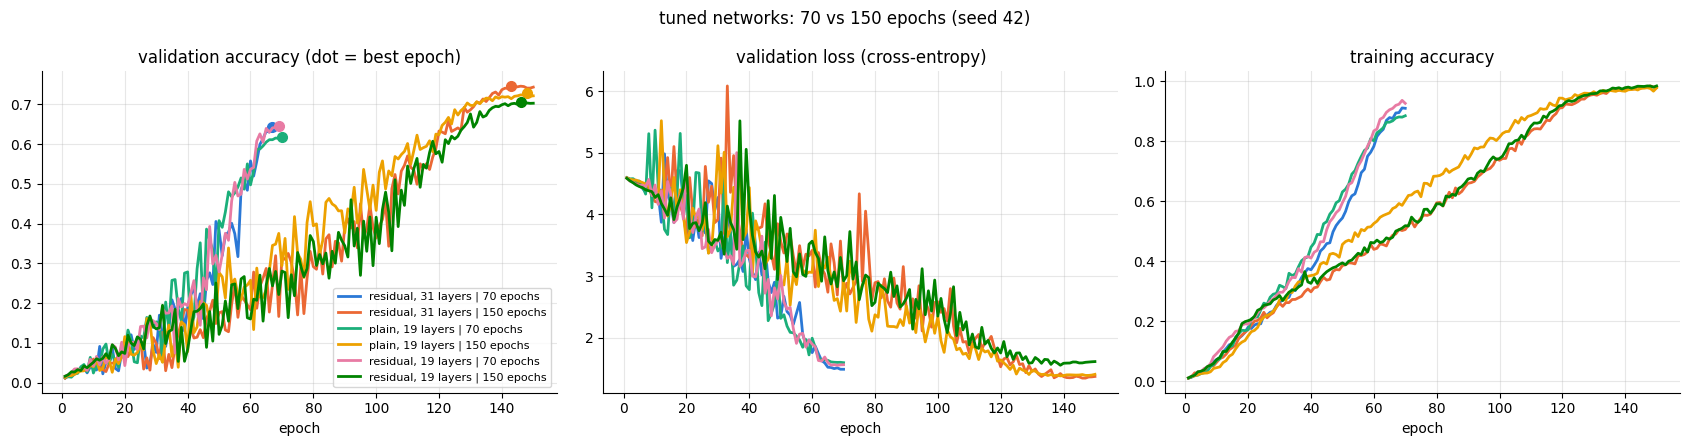

In [ ]:
names = finalists(TUNE_N) or []
groups = {}
for name in names:
    if best_tuned(name):
        groups[f"{label(name)} | {BASE['epochs']} epochs"] = best_tuned(name)[1]
    if long_runs(name):
        groups[f"{label(name)} | {LONG_EPOCHS} epochs"] = long_runs(name)
if groups:
    display(seed_summary(groups))

runs = long_final()
if runs:
    ranked, final = select(runs, f"{LONG_EPOCHS} epochs: ")
    print("final configuration:", run_overrides(runs[final][0]))
    curves = {}
    for n in ranked:
        curves[f"{label(n)} | {BASE['epochs']} epochs"] = best_tuned(n)[1][0]
        curves[f"{label(n)} | {LONG_EPOCHS} epochs"] = runs[n][0]
    plot_curves(curves, f"tuned networks: {BASE['epochs']} vs {LONG_EPOCHS} epochs (seed 42)")

**Longer training adds 7–10 points** to every network, with no other change: at 70 epochs they were stopped too early.
**Overfitting does not increase**: the train–validation gap of the 31-layer residual network goes from 26 points at 70 epochs to 24 at
150, so the recipe tuned for 70 epochs still controls overfitting with a longer budget.

**The ranking changes.** At 150 epochs the 31-layer residual network is 1.6 points better than the second network, more than twice the
run-to-run noise, so by our selection rule it is the final model: the deepest residual network benefits most from the
additional training. Training only the winner at 70 epochs longer would have missed it.

**Final model: the 31-layer residual network** (stem of three 3x3 convolutions; four
stages of 3, 4, 6 and 1 basic blocks with 64, 128, 256 and 512 channels; global average pooling; linear classifier;
11.9M parameters), trained for 150 epochs with SGD (momentum 0.9), a one-cycle schedule peaking at a learning rate of 0.05, weight
decay 5e-3, label smoothing 0.2, random resized crops of at least 50% of the image, horizontal flips and random
erasing (p = 0.25): **74.0% ± 0.7 validation and 74.2% ± 0.2 test accuracy**. It combines every component justified
by the previous experiments — BatchNorm, global average pooling, augmentation, a fourth stage, depth and residual
connections — with a tuned training recipe.

## 5. Ablation of the final model

The roadmap and the depth experiment *added* components one at a time to a plain network. To prove that every
design choice of the **final model** contributes to its accuracy, we now do the converse: starting from the final
network with its final configuration (150 epochs), we **remove one component at a time**, retrain, and compare with the
full model. Every ablation uses the same three seeds and changes exactly one thing; learning rate, epochs and all the
other settings stay those of the final model.

| ablation | what changes | component tested |
|---|---|---|
| `no_batchnorm` | BatchNorm removed (convolutions get a bias back) | architecture |
| `no_gap` | flatten + linear head instead of global average pooling | architecture |
| `no_residual` | skip connections removed (plain network) | architecture |
| `no_stage4` | the 512-channel stage removed | architecture |
| `shallow` | one block per stage instead of the final layout | architecture |
| `no_augmentation` | no random resized crop and no horizontal flip | training recipe |
| `no_erasing` | no random erasing | training recipe |
| `no_label_smoothing` | plain cross-entropy | training recipe |
| `no_weight_decay` | weight decay 0 | training recipe |
| `cosine` | cosine schedule with warmup instead of one-cycle | training recipe |
| `no_batchnorm_lr0.01`, `no_gap_lr0.01` | the same removals at a learning rate of 0.01 | control |

**Control.** In the roadmap, networks without BatchNorm or with the flatten head were unstable at the high learning
rates that the final model uses. A removal could then look harmful only because the learning rate does not suit it, as
in the learning-rate sweep of the roadmap: for these two components we also train the removal at lr 0.01, and report
both.

**Reading the table.** `Δ val` is the validation accuracy of the ablated network minus that of the full model; a
component is useful if removing it lowers the accuracy by more than the seed noise (`beyond noise`: the drop exceeds
the larger standard deviation of the two). The train accuracy tells *how* a component helps: removing a regularizer
raises the train-validation gap, removing capacity or an optimization aid lowers the train accuracy itself.

In [ ]:
# The final model (selected above) and its ablations: each one changes exactly one component of its configuration
FINAL_NET = final_network()
ABLATION_GROUP = "ablation"
ABLATION_LR_CONTROL = (
    0.01  # lr of the control runs for the components that make training unstable
)


def make_ablations(base):
    # {name: (kind, overrides)} on top of the configuration `base` of the final model; removals that would not
    # change `base` (e.g. no_residual on a plain network) are left out.
    channels, blocks = tuple(base["channels"]), tuple(base["blocks"])
    candidates = {
        "no_batchnorm": ("architecture", dict(batchnorm=False)),
        "no_gap": ("architecture", dict(gap=False)),
        "no_residual": ("architecture", dict(residual=False)),
        "no_stage4": ("architecture", dict(channels=channels[:3], blocks=blocks[:3])),
        "shallow": ("architecture", dict(blocks=(1,) * len(blocks))),
        "no_augmentation": ("recipe", dict(augment=False)),
        "no_erasing": ("recipe", dict(random_erasing=0.0)),
        "no_label_smoothing": ("recipe", dict(label_smoothing=0.0)),
        "no_weight_decay": ("recipe", dict(weight_decay=0.0)),
        "cosine": ("recipe", dict(schedule="cosine")),
        "no_batchnorm_lr0.01": ("control", dict(batchnorm=False, lr=ABLATION_LR_CONTROL)),
        "no_gap_lr0.01": ("control", dict(gap=False, lr=ABLATION_LR_CONTROL))
    }
    same = lambda a, b: json.dumps(a) == json.dumps(b)  # tuples and lists compare equal
    return {
        n: (kind, over)
        for n, (kind, over) in candidates.items()
        if any(not same(base.get(k), v) for k, v in over.items())
    }


if FINAL_NET is None or not long_runs(FINAL_NET):
    ABLATION_BASE, ABLATIONS = None, {}
    print("the final model is not available yet: train the longer runs first")
else:
    ABLATION_BASE = run_overrides(long_runs(FINAL_NET)[0])
    ABLATIONS = make_ablations(ABLATION_BASE)
    print(
        f"final model: {FINAL_NET}, {ABLATION_BASE['epochs']} epochs, lr {ABLATION_BASE['lr']:g}"
    )
    for name, (kind, over) in ABLATIONS.items():
        print(f"{name:22s} {kind:13s} {over}")

final model: res_3461, 150 epochs, lr 0.05
no_batchnorm           architecture  {'batchnorm': False}
no_gap                 architecture  {'gap': False}
no_residual            architecture  {'residual': False}
no_stage4              architecture  {'channels': (64, 128, 256), 'blocks': (3, 4, 6)}
shallow                architecture  {'blocks': (1, 1, 1, 1)}
no_augmentation        recipe        {'augment': False}
no_erasing             recipe        {'random_erasing': 0.0}
no_label_smoothing     recipe        {'label_smoothing': 0.0}
no_weight_decay        recipe        {'weight_decay': 0.0}


In [ ]:
# [run]
for name, (kind, over) in ABLATIONS.items():
    for seed in SEEDS:
        run_experiment(
            f"{name}_s{seed}",
            ABLATION_GROUP,
            note=f"ablation: {name}",
            **{**ABLATION_BASE, **over, "seed": seed},
        )
report_runs()

skip ablation/no_batchnorm_s42: best val 0.011 (already trained)
skip ablation/no_batchnorm_s43: best val 0.010 (already trained)
skip ablation/no_batchnorm_s44: best val 0.010 (already trained)
skip ablation/no_gap_s42: best val 0.520 (already trained)
skip ablation/no_gap_s43: best val 0.508 (already trained)
skip ablation/no_gap_s44: best val 0.511 (already trained)
skip ablation/no_residual_s42: best val 0.540 (already trained)
skip ablation/no_residual_s43: best val 0.584 (already trained)
skip ablation/no_residual_s44: best val 0.575 (already trained)
skip ablation/no_stage4_s42: best val 0.731 (already trained)
skip ablation/no_stage4_s43: best val 0.726 (already trained)
skip ablation/no_stage4_s44: best val 0.723 (already trained)
skip ablation/shallow_s42: best val 0.657 (already trained)
skip ablation/shallow_s43: best val 0.658 (already trained)
skip ablation/shallow_s44: best val 0.655 (already trained)
skip ablation/no_augmentation_s42: best val 0.560 (already trained)
sk

### Results of the ablation

Mean ± standard deviation over three seeds, each ablated network against the full model (the longer training of the
final network, same seeds). Runs that diverged before the first validation have no checkpoint and are left out of the
means (`diverged` counts them).

In [ ]:
def ablation_table():
    # One row per configuration: full model first, then the ablations; None until at least one run exists.
    runs = load_group(ABLATION_GROUP)
    groups = {"full model": ("", {}, long_runs(FINAL_NET))}
    for name, (kind, over) in ABLATIONS.items():
        got = [runs[f"{name}_s{s}"] for s in SEEDS if f"{name}_s{s}" in runs]
        if got:
            groups[name] = (kind, over, got)
    if len(groups) == 1:
        return None

    def stats(rs, key):
        v = np.array([r[key] for r in rs if r["best_epoch"] > 0], dtype=float)
        return (
            (v.mean(), v.std(ddof=1) if len(v) > 1 else np.nan)
            if len(v)
            else (np.nan, np.nan)
        )

    ref_val, ref_test = (
        stats(groups["full model"][2], "best_val_acc"),
        stats(groups["full model"][2], "test_acc"),
    )
    rows = []
    for name, (kind, over, rs) in groups.items():
        val, test = stats(rs, "best_val_acc"), stats(rs, "test_acc")
        train, gap = (
            stats(rs, "final_train_acc")[0],
            np.nanmean([r["final_train_acc"] - r["final_val_acc"] for r in rs]),
        )
        noise = np.nanmax([val[1], ref_val[1]])
        rows.append(
            dict(
                run=name,
                kind=kind,
                change=", ".join(f"{k}={v}" for k, v in over.items()),
                lr=rs[0]["config"]["lr"],
                params_M=rs[0]["params"] / 1e6,
                seeds=len(rs),
                diverged=f"{sum(r['diverged'] for r in rs)}/{len(rs)}",
                val_mean=val[0],
                val_std=val[1],
                d_val=val[0] - ref_val[0],
                test_mean=test[0],
                test_std=test[1],
                d_test=test[0] - ref_test[0],
                train=train,
                gap=gap,
                beyond_noise=(
                    ""
                    if name == "full model"
                    else "yes"
                    if ref_val[0] - val[0] > noise
                    else "no"
                ),
            )
        )
    return pd.DataFrame(rows).set_index("run")


def style_ablation(table):
    return (
        table.rename(
            columns={
                "d_val": "Δ val",
                "d_test": "Δ test",
                "val_mean": "val",
                "val_std": "± val",
                "test_mean": "test",
                "test_std": "± test",
                "train": "train acc",
                "gap": "train-val gap",
                "params_M": "params (M)",
                "beyond_noise": "beyond noise",
            }
        )
        .style.format(
            {
                "lr": "{:g}",
                "params (M)": "{:.2f}",
                "val": "{:.3f}",
                "± val": "{:.3f}",
                "Δ val": "{:+.3f}",
                "test": "{:.3f}",
                "± test": "{:.3f}",
                "Δ test": "{:+.3f}",
                "train acc": "{:.3f}",
                "train-val gap": "{:+.3f}",
            },
            na_rep="-",
        )
        .background_gradient(
            subset=["Δ val", "Δ test"], cmap="RdYlGn", vmin=-0.4, vmax=0.4
        )
        .set_properties(
            subset=pd.IndexSlice["full model", :], **{"font-weight": "bold"}
        )
    )


ablation = ablation_table() if FINAL_NET is not None and long_runs(FINAL_NET) else None
if ablation is None:
    print("no ablation run yet: run the cell above")
else:
    display(style_ablation(ablation))

,kind,change,lr,params (M),seeds,diverged,val,± val,Δ val,test,± test,Δ test,train acc,train-val gap,beyond noise
run,,,,,,,,,,,,,,,
full model,,,0.05,11.91,3,0/3,0.740,0.007,+0.000,0.742,0.002,+0.000,0.982,+0.244,
no_batchnorm,architecture,batchnorm=False,0.05,11.91,3,0/3,0.010,0.000,-0.730,0.010,0.000,-0.732,0.010,+0.000,yes
no_gap,architecture,gap=False,0.05,14.37,3,0/3,0.513,0.006,-0.227,0.518,0.005,-0.224,0.990,+0.481,yes
no_residual,architecture,residual=False,0.05,11.74,3,0/3,0.566,0.023,-0.174,0.571,0.016,-0.171,0.690,+0.126,yes
no_stage4,architecture,"channels=(64, 128, 256), blocks=(3, 4, 6)",0.05,8.22,3,0/3,0.727,0.004,-0.014,0.726,0.004,-0.016,0.979,+0.255,yes
shallow,architecture,"blocks=(1, 1, 1, 1)",0.05,4.98,3,0/3,0.657,0.002,-0.084,0.655,0.004,-0.087,0.989,+0.334,yes
no_augmentation,recipe,augment=False,0.05,11.91,3,0/3,0.562,0.006,-0.179,0.571,0.005,-0.172,0.999,+0.442,yes
no_erasing,recipe,random_erasing=0.0,0.05,11.91,3,0/3,0.744,0.004,+0.003,0.738,0.004,-0.004,1.000,+0.260,no
no_label_smoothing,recipe,label_smoothing=0.0,0.05,11.91,3,0/3,0.722,0.004,-0.018,0.727,0.008,-0.015,0.979,+0.259,yes


The two plots below show the same table. **Left**: the change in validation (dark bars) and test (light bars) accuracy
caused by each removal, with the standard deviation over seeds (the grey band is the seed noise of the full model); components are ordered by how much their removal costs.
**Right**: where each network ends up in the training accuracy / validation accuracy plane. A network far below the
dashed diagonal overfits. Removing capacity or an optimization aid moves a network to the left (it fits its training
set worse); removing a regularizer moves it to the right and down (it fits better and generalizes worse).

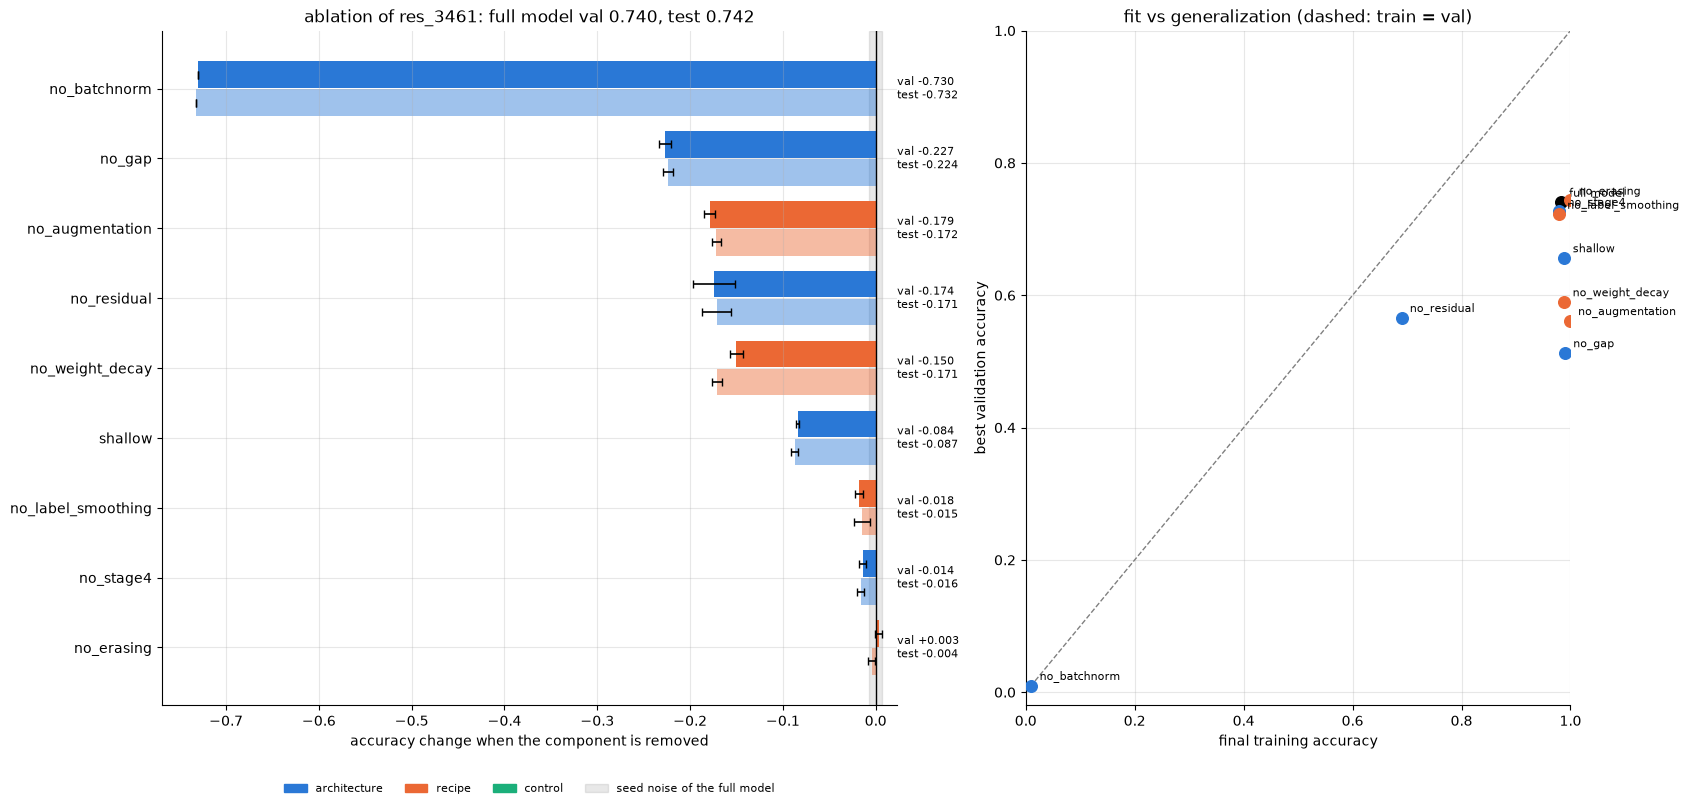

In [ ]:
if ablation is not None:
    full = ablation.loc["full model"]
    abl = ablation.drop(index="full model").sort_values(
        "d_val", ascending=True
    )  # the most costly removal on top
    kind_color = {"architecture": COLORS[0], "recipe": COLORS[1], "control": COLORS[2]}
    ys = np.arange(len(abl))

    fig, (ax, ax2) = plt.subplots(
        1,
        2,
        figsize=(17, 0.55 * len(abl) + 3.2),
        gridspec_kw=dict(width_ratios=[1.35, 1]),
    )
    ax.axvspan(-full.val_std, full.val_std, color="gray", alpha=0.18)
    ax.barh(
        ys - 0.2,
        abl.d_val,
        0.38,
        xerr=abl.val_std.fillna(0),
        color=[kind_color[k] for k in abl.kind],
        error_kw=dict(lw=1.2, capsize=3),
    )
    ax.barh(
        ys + 0.2,
        abl.d_test,
        0.38,
        xerr=abl.test_std.fillna(0),
        color=[kind_color[k] for k in abl.kind],
        alpha=0.45,
        error_kw=dict(lw=1.2, capsize=3),
    )
    right = max(0.02, np.nanmax(abl.d_val) + 0.02)
    for y, d, t in zip(ys, abl.d_val, abl.d_test):
        ax.text(
            right, y, f"val {d:+.3f}\ntest {t:+.3f}", va="center", ha="left", fontsize=8
        )
    ax.set_xlim(None, right)
    ax.set_yticks(ys, abl.index)
    ax.invert_yaxis()
    ax.axvline(0, color="black", lw=1)
    ax.set_xlabel("accuracy change when the component is removed")
    ax.set_title(
        f"ablation of {FINAL_NET}: full model val {full.val_mean:.3f}, test {full.test_mean:.3f}"
    )
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in kind_color.values()]
    band = plt.Rectangle((0, 0), 1, 1, color="gray", alpha=0.18)
    ax.legend(
        handles + [band],
        list(kind_color) + ["seed noise of the full model"],
        loc="upper center",
        bbox_to_anchor=(0.5, -0.1),
        ncol=4,
        fontsize=8,
        frameon=False,
    )

    lim = [np.nanmin(ablation.val_mean) - 0.03, 1.0]
    ax2.plot([0, 1], [0, 1], "--", color="gray", lw=1)
    for name, row in ablation.iterrows():
        c = "black" if name == "full model" else kind_color[row.kind]
        ax2.scatter(row.train, row.val_mean, color=c, s=70, zorder=3)
        ax2.annotate(
            name,
            (row.train, row.val_mean),
            textcoords="offset points",
            xytext=(6, 4),
            fontsize=8,
        )
    ax2.set_xlim(max(np.nanmin(ablation.train) - 0.05, 0), 1.0)
    ax2.set_ylim(*lim)
    ax2.set_xlabel("final training accuracy")
    ax2.set_ylabel("best validation accuracy")
    ax2.set_title("fit vs generalization (dashed: train = val)")
    plt.tight_layout()
    plt.show()

Training curves of every ablation (seed 42) against the full model: validation accuracy (solid) and training accuracy
(dashed).

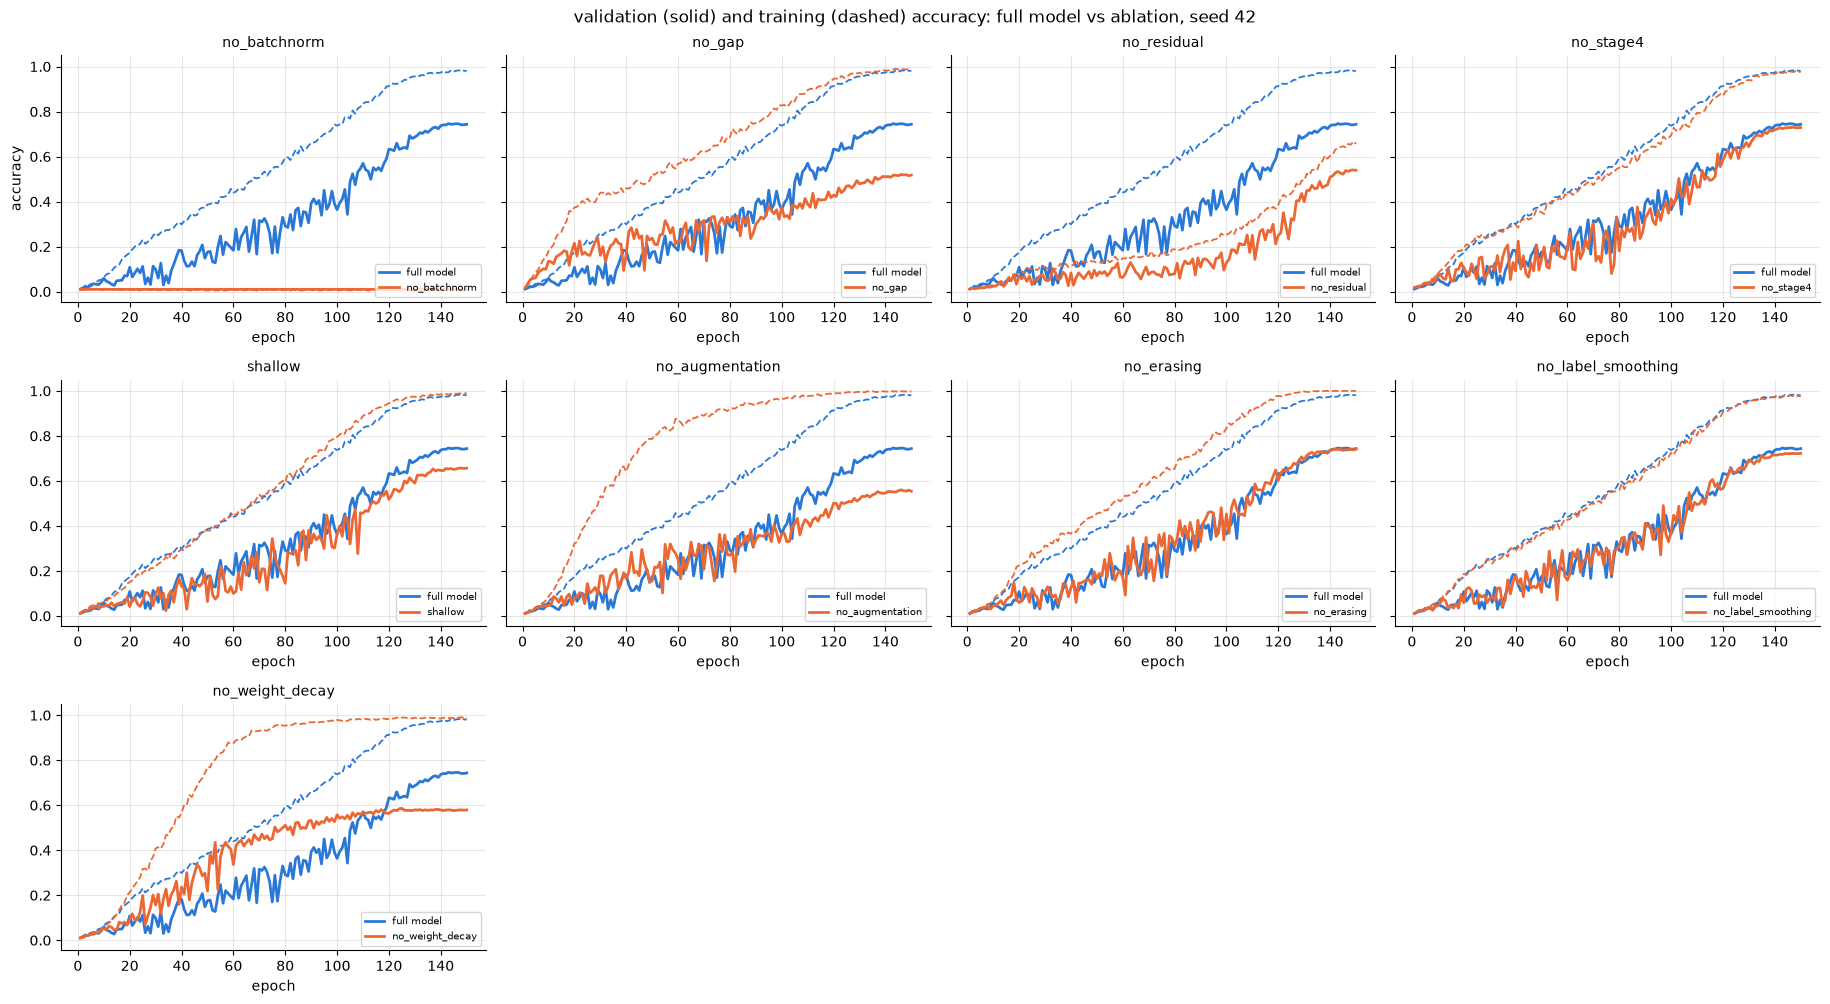

In [ ]:
if ablation is not None:
    runs = load_group(ABLATION_GROUP)
    names = [n for n in ablation.index if n != "full model"]
    reference = long_runs(FINAL_NET)[0]
    cols = 4
    rows_ = int(np.ceil(len(names) / cols))
    fig, axes = plt.subplots(
        rows_, cols, figsize=(4.6 * cols, 3.4 * rows_), sharey=True, squeeze=False
    )
    for ax, name in zip(axes.ravel(), names):
        r = runs[f"{name}_s{SEEDS[0]}"] if f"{name}_s{SEEDS[0]}" in runs else None
        for label, run, color in (
            ("full model", reference, COLORS[0]),
            (name, r, COLORS[1]),
        ):
            if run is None or not run["history"]["val_acc"]:
                continue
            h = run["history"]
            ep = range(1, len(h["val_acc"]) + 1)
            ax.plot(ep, h["val_acc"], color=color, label=label)
            ax.plot(ep, h["train_acc"], color=color, ls="--", lw=1.3)
        ax.set_title(name, fontsize=10)
        ax.set_xlabel("epoch")
        ax.legend(fontsize=7, loc="lower right")
    for ax in axes.ravel()[len(names) :]:
        ax.axis("off")
    axes[0, 0].set_ylabel("accuracy")
    fig.suptitle(
        "validation (solid) and training (dashed) accuracy: full model vs ablation, seed 42"
    )
    plt.tight_layout()
    plt.show()

## 6. Error analysis of the final model

Where does the final model fail? We use the test predictions stored with each run: the per-class accuracy of the
three seeds and the pairs of variants the model confuses most often (seed 42). Class names are shown when the dataset
is available.

,true,predicted,errors,share_of_class
0,DC-3,C-47,13,38%
1,C-47,DC-3,11,33%
2,747-200,747-300,10,29%
3,747-400,747-300,8,24%
4,767-300,767-200,8,24%
5,MD-90,MD-80,7,21%
6,E-190,E-195,7,21%
7,747-300,747-100,7,21%
8,747-300,747-200,7,21%
9,A310,A300B4,7,21%


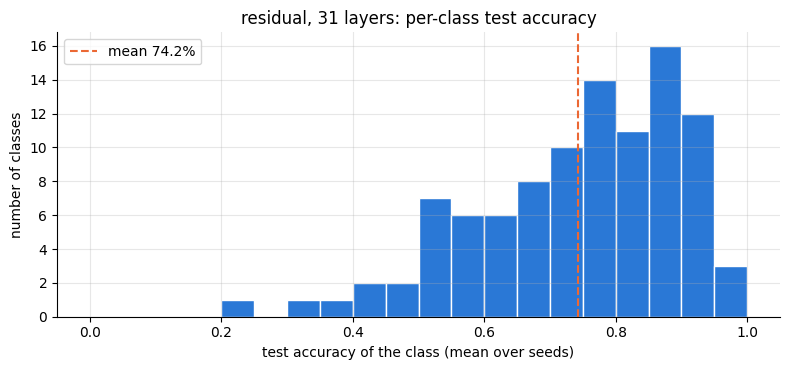

hardest classes: 747-200 (25%), DC-3 (32%), 747-300 (38%), C-47 (42%), 747-400 (43%)


In [ ]:
final = final_network()
if final is None:
    print("train the longer runs first")
else:
    names_of = globals().get("CLASSES") or [f"class {i}" for i in range(N_CLASSES)]
    runs = long_runs(final)

    # per-class test accuracy, mean over the seeds
    per_class = []
    for r in runs:
        true, pred = np.array(r["test_true"]), np.array(r["test_pred"])
        per_class.append(np.bincount(true, weights=(pred == true), minlength=N_CLASSES) / np.bincount(true, minlength=N_CLASSES))
    per_class = np.mean(per_class, axis=0)

    # most frequent confusions (seed 42)
    true, pred = np.array(runs[0]["test_true"]), np.array(runs[0]["test_pred"])
    cm = np.zeros((N_CLASSES, N_CLASSES), dtype=int)
    np.add.at(cm, (true, pred), 1)
    off = cm.copy(); np.fill_diagonal(off, 0)
    top = np.dstack(np.unravel_index(np.argsort(off, axis=None)[::-1][:10], off.shape))[0]
    display(pd.DataFrame([dict(true=names_of[t], predicted=names_of[p], errors=off[t, p],
                               share_of_class=off[t, p] / cm[t].sum()) for t, p in top])
            .style.format({"share_of_class": "{:.0%}"}))

    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.hist(per_class, bins=np.linspace(0, 1, 21), color=COLORS[0], edgecolor="white")
    ax.axvline(per_class.mean(), color=COLORS[1], ls="--", lw=1.5, label=f"mean {per_class.mean():.1%}")
    ax.set_xlabel("test accuracy of the class (mean over seeds)"); ax.set_ylabel("number of classes")
    ax.set_title(f"{label(final)}: per-class test accuracy"); ax.legend()
    plt.tight_layout(); plt.show()
    worst = np.argsort(per_class)[:5]
    print("hardest classes:", ", ".join(f"{names_of[i]} ({per_class[i]:.0%})" for i in worst))

A fine-grained task is expected to concentrate its errors on visually similar variants rather than spreading them
uniformly: the pairs above show which variants the model cannot yet separate, and the per-class accuracy shows how
unevenly the 100 classes are learned.

## Conclusions

- A plain CNN memorizes the 33 images per class of FGVC-Aircraft; BatchNorm, global average pooling and augmentation
  turn memorization into generalization (18.5% → 47.7%), and a fourth stage adds capacity (52.6%).
- Deeper plain networks degrade, while residual networks keep improving with depth — but without regularization the
  ease of fitting of residual networks becomes overfitting.
- A tuned training recipe (strong weight decay, label smoothing, random erasing, one-cycle schedule) reverses that
  ranking and brings every network to 63–64%; training for 150 epochs adds 7–10 more points.
- The final model, a 31-layer residual network, reaches **74.2% ± 0.2 test accuracy**, with every component justified
  by a measurement.

# Part 2: fine-tune a pretrained ResNet-18

We now fine-tune the ResNet-18 of PyTorch (`torchvision.models.resnet18`), pretrained on ImageNet-1K (V1), on the same
data, split and evaluation protocol of Part 1. Everything defined above is reused as is: data pipeline and
augmentation, training loop (`fit`), experiment runner (`run_experiment`), storage of the results and plots. The
**only two differences** with respect to Part 1 are handled by the configuration key `pretrained=True`:

1. the network: `build_model` returns the pretrained ResNet-18 with a new 100-way classifier
   (`Dropout -> Linear(512, 100)`, initialized at random) instead of `AircraftNet`;
2. the input normalization: the pretrained weights expect the mean and standard deviation of ImageNet
   (`get_data(..., imagenet_stats=True)`), not those of our training split.

Results are stored in `results/part2A`.

## 2A: the hyperparameters of Part 1

As the assignment requires, we fine-tune the whole ResNet-18 with the **training hyperparameters of the best model of
Part 1** (`res_3461`, with its tuned recipe, trained for the final 150 epochs), and nothing else is tuned:

| hyperparameter | value |
|---|---|
| resolution, batch size | 224 x 224, 64 |
| epochs | 150 (`LONG_EPOCHS`) |
| optimizer | SGD, momentum 0.9 |
| learning rate, schedule | 0.05, one-cycle (rise over the first 30% of the epochs, then cosine decay) |
| weight decay | 5e-3 (convolution and linear weights only) |
| label smoothing, dropout | 0.2, 0 |
| augmentation | random resized crop (50-100% of the area) + horizontal flip, random erasing (p = 0.25) |
| seeds | 42, 43, 44 |

All layers are fine-tuned with this single learning rate. The learning rate of 0.05 was tuned for a network trained
from scratch; this experiment shows how it behaves on pretrained weights, which is the starting point of 2B.

In [ ]:
# the training hyperparameters of the best model of Part 1 (res_3461, configuration cfg05), applied to the pretrained net
FINETUNE = dict(
    pretrained=True,
    augment=True,
    crop_scale=(0.5, 1.0),
    dropout=0.0,
    epochs=LONG_EPOCHS,
    lr=0.05,
    weight_decay=5e-3,
    label_smoothing=0.2,
    random_erasing=0.25,
    schedule="onecycle",
)

# sanity check: same recipe as the stored best configuration of res_3461 in Part 1, when it is available
best = best_tuned(FINAL_NET) if FINAL_NET else None
if best is not None:
    stored = run_overrides(best[1][0])
    differences = {
        k: (stored.get(k), v)
        for k, v in FINETUNE.items()
        if k not in ("pretrained", "epochs")
        and json.loads(json.dumps(stored.get(k))) != json.loads(json.dumps(v))
    }
    print(
        "same recipe as Part 1"
        if not differences
        else f"WARNING: differs from Part 1 (part 1, here): {differences}"
    )

same recipe as Part 1


Layer (type (var_name))                  Output Shape              Param #
ResNet (ResNet)                          [1, 100]                  --
├─Conv2d (conv1)                         [1, 64, 112, 112]         9,408
├─BatchNorm2d (bn1)                      [1, 64, 112, 112]         128
├─ReLU (relu)                            [1, 64, 112, 112]         --
├─MaxPool2d (maxpool)                    [1, 64, 56, 56]           --
├─Sequential (layer1)                    [1, 64, 56, 56]           --
│    └─BasicBlock (0)                    [1, 64, 56, 56]           --
│    │    └─Conv2d (conv1)               [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d (bn1)            [1, 64, 56, 56]           128
│    │    └─ReLU (relu)                  [1, 64, 56, 56]           --
│    │    └─Conv2d (conv2)               [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d (bn2)            [1, 64, 56, 56]           128
│    │    └─ReLU (relu)                  [1, 64, 56, 56]           --
│

### Fine-tuning

Three seeds, same configuration: there is no learning-rate sweep, so the mean over the seeds is not biased by a
selection (in Part 1 the seed-42 run of a configuration is the best of three learning rates).

In [ ]:
# [run]
for seed in SEEDS:
    run_experiment(
        f"resnet18_ft_s{seed}",
        "finetune",
        note="hyperparameters of part 1",
        results_dir=RESULTS_DIR_2A,
        seed=seed,
        **FINETUNE,
    )
report_runs()

skip finetune/resnet18_ft_s42: best val 0.719 (already trained)
skip finetune/resnet18_ft_s43: best val 0.726 (already trained)
skip finetune/resnet18_ft_s44: best val 0.712 (already trained)


### Results of 2A

Mean ± standard deviation over three seeds, compared with the best model of Part 1 trained from scratch with the same
hyperparameters (`res_3461`, 150 epochs). The curves are the seed-42 runs.

,lr,seeds,params_M,val_mean,val_std,test_mean,test_std,train_mean
run,,,,,,,,
"resnet18_ft (pretrained, 2A)",0.05,3,11.23,0.719,0.007,0.724,0.007,0.993
"res_3461 (from scratch, part 1)",0.05,3,11.91,0.740,0.007,0.742,0.002,0.982


resnet18_ft (pretrained, 2A)     val 0.719 ± 0.007 | test 0.724 ± 0.007 | train 0.993
res_3461 (from scratch, part 1)  val 0.740 ± 0.007 | test 0.742 ± 0.002 | train 0.982


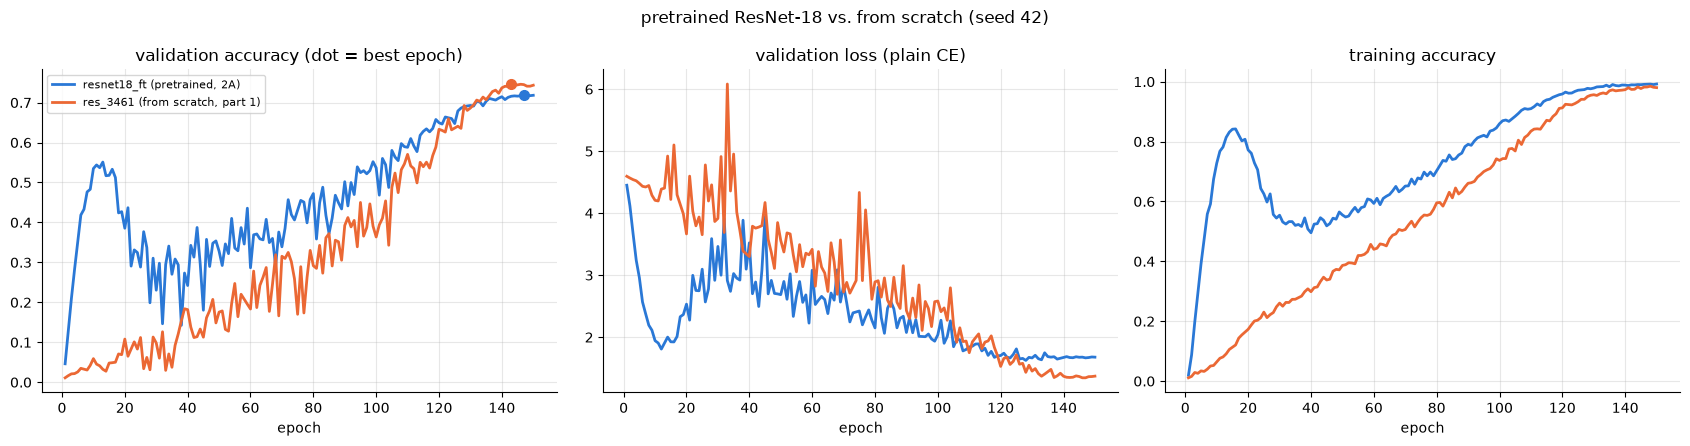

In [ ]:
finetune = load_group("finetune", RESULTS_DIR_2A)
groups = {
    "resnet18_ft (pretrained, 2A)": list(finetune.values()),
    f"{FINAL_NET} (from scratch, part 1)": long_runs(FINAL_NET) if FINAL_NET else [],
}
groups = {k: v for k, v in groups.items() if v}
if groups:
    display(seed_summary(groups))
    for label, runs in groups.items():
        print(
            f"{label:32s} val {seed_mean(runs):.3f} ± {seed_std(runs):.3f} | "
            f"test {seed_mean(runs, 'test_acc'):.3f} ± {seed_std(runs, 'test_acc'):.3f} | "
            f"train {seed_mean(runs, 'final_train_acc'):.3f}"
        )
    plot_curves(
        {label: runs[0] for label, runs in groups.items()},
        "pretrained ResNet-18 vs. from scratch (seed 42)",
    )
else:
    print("no stored run yet")

One row per seed of the fine-tuning: epoch of the best validation accuracy, training accuracy at the last epoch and
train-validation gap.

,lr,params_M,best_val,best_epoch,final_train,gap,test,minutes
run,,,,,,,,
resnet18_ft_s42,0.05,11.23,0.719,147,0.992,+0.274,0.724,2.2
resnet18_ft_s43,0.05,11.23,0.726,146,0.993,+0.271,0.731,2.2
resnet18_ft_s44,0.05,11.23,0.712,143,0.995,+0.286,0.718,2.2


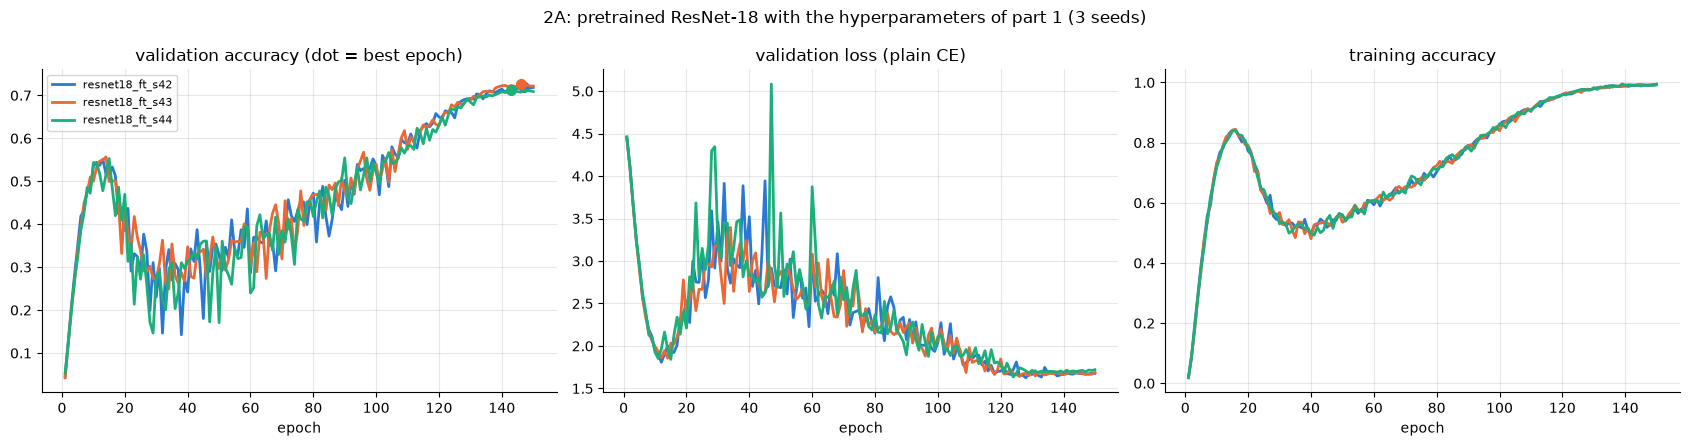

In [ ]:
if finetune:
    display(summary(finetune))
    plot_curves(
        finetune,
        "2A: pretrained ResNet-18 with the hyperparameters of part 1 (3 seeds)",
    )

## 2B: tuned fine-tuning

*To be added.*